# SMP1 · Session 6
## Random sampling, Monte Carlo and limit theorems



## Setup before Slide 1

Run this cell once after starting or restarting the kernel. NumPy handles arrays
and random draws; pandas displays tables; Matplotlib draws figures; SciPy supplies
normal-distribution probabilities. `%matplotlib inline` puts the plots in the
notebook. The rest of the setup only controls display style.

<a id="ppt-setup"></a>

**PowerPoint: Setup.** Before the presentation. Run setup once, then work down the notebook in slide order. No advance Run All is required. Keep the kernel running between demonstrations. Return to **Slide 1** after the demonstration. [Slide index](#powerpoint-index).


In [1]:
# PowerPoint: Setup — Before the presentation
# After this demonstration: return to Slide 1.
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

BLUE, ORANGE = "#2D75A3", "#C96B16"
GREEN, RED = "#2F6F4E", "#A83B32"
plt.rcParams.update({
    "figure.figsize": (10, 4.4), "figure.dpi": 110,
    "font.size": 12, "axes.titlesize": 15, "axes.labelsize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.18,
    "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE, GREEN, RED]),
})
pd.set_option("display.max_columns", 8)
pd.set_option("display.precision", 5)
print("Ready. Run the notebook from top to bottom.")

Ready. Run the notebook from top to bottom.


<a id="warehouse"></a>
## Slide 4: One simulated morning

There are **50 orders** each morning. The orders are independent, and each follows
the same distribution:

| Items in an order, $x$ | 1 | 2 | 6 |
|:--|--:|--:|--:|
| $P(X=x)$ | 0.60 | 0.30 | 0.10 |

An order's size is random. The distribution is the rule that specifies how likely
the possible sizes are. **We specify the model before we simulate it.**

The warehouse can handle **110 items**. One trial means one complete morning:
draw 50 orders and add their item counts.

**Predict:** must a morning contain exactly 30 one-item orders, 15 two-item orders
and 5 six-item orders?

<a id="ppt-slide-4"></a>

**PowerPoint: Slide 4.** One simulated morning. The slide shows an illustrative batch. This cell generates a real simulated batch, so its counts need not match the slide. Return to **Slide 5** after the demonstration. [Slide index](#powerpoint-index).


In [8]:
# PowerPoint: Slide 4 — One simulated morning
# After this demonstration: return to Slide 5.
# The baseline model, shared by the warehouse demonstrations.
ORDER_VALUES = np.array([1, 2, 6])
ORDER_PROBS = np.array([0.60, 0.30, 0.10])
ORDERS_PER_MORNING = 50
CAPACITY = 110

rng_one = np.random.default_rng()
one_morning = rng_one.choice(ORDER_VALUES, size=ORDERS_PER_MORNING,
                            p=ORDER_PROBS)
counts = np.array([(one_morning == x).sum() for x in ORDER_VALUES])
display(pd.DataFrame({"Items per order": ORDER_VALUES,
                      "Number of orders": counts,
                      "Total items": ORDER_VALUES * counts}))
print(f"Orders: {counts.sum()}   Workload: {one_morning.sum()} items")
print(f"Within capacity: {one_morning.sum() <= CAPACITY}")

,Items per order,Number of orders,Total items
0,1,34,34
1,2,11,22
2,6,5,30


Orders: 50   Workload: 86 items
Within capacity: True


## Slide 5: Where the randomness comes from

Think of drawing a ticket from a well-mixed bag, replacing it, and drawing again.
A computer uses a **pseudorandom number generator** to imitate independent draws.
Its seed determines a reproducible sequence; the model determines the probabilities.

Here is one way to turn a uniform draw $U$ into an order:

$$X=\begin{cases}
1,&0\le U<0.60,\\
2,&0.60\le U<0.90,\\
6,&0.90\le U<1.
\end{cases}$$

Because a uniform draw lands in an interval with probability equal to its length,
these intervals produce probabilities 0.60, 0.30 and 0.10. `rng.choice` draws from
the same specified categorical distribution; this is a transparent illustration,
not a claim about its internal implementation.

**Predict:** which output occurs most often in these 12 draws? Need the proportions
match the probabilities exactly?

<a id="ppt-slide-5"></a>

**PowerPoint: Slide 5 · Optional.** Where the randomness comes from. Return to **Slide 6** after the demonstration. [Slide index](#powerpoint-index).


In [7]:
# PowerPoint: Slide 5 — Where the randomness comes from
# After this demonstration: return to Slide 6.
rng_map = np.random.default_rng(12)
u_demo = rng_map.random(12)
orders_from_u = np.where(u_demo < 0.60, 1, np.where(u_demo < 0.90, 2, 6))
display(pd.DataFrame({"Uniform draw U": u_demo.round(3),
                      "Resulting order X": orders_from_u}))

,Uniform draw U,Resulting order X
0,0.251,1
1,0.947,6
2,0.189,1
3,0.179,1
4,0.350,1
5,0.231,1
6,0.670,2
7,0.115,1
8,0.896,2
9,0.858,2


## Slide 6: The expected workload

The probabilities describe a long-run pattern. They do not impose exact
proportions within each group of 50 draws. Forcing the counts to be 30, 15 and 5
would remove the fluctuations we need to study.

From SMP 2, the expected size of one order is

$$E[X]=1(0.60)+2(0.30)+6(0.10)=1.8.$$

Writing $S_{50}=X_1+\cdots+X_{50}$ for a morning's total, linearity of expectation gives

$$E[S_{50}]=50E[X]=90.$$

**90 is an average workload, not a capacity probability.** A probability must lie
between 0 and 1. Knowing the mean alone does not tell us how often the workload
exceeds 110.

**Try:** change the seed in the [Slide 4 cell](#ppt-slide-4). The counts and total may change;
the model probabilities and the expected workload do not.

<a id="sampling"></a>
## Slide 11: Samples and sampling distributions

The phrase **independent and identically distributed**, abbreviated **i.i.d.**,
means that the observations are independent and each follows the same distribution.
Our warehouse model assumes this for the orders. We also simulate complete mornings
independently of one another.

A **statistic** is a quantity calculated from a sample. For example,

$$\bar X_n=\frac1n\sum_{j=1}^n X_j$$

is the sample mean. A new sample usually gives a new mean. The distribution of
those means across repeated samples of size $n$ is its **sampling distribution**.

For a clean first experiment, let $X\sim\operatorname{Uniform}(0,1)$, so
$E[X]=1/2$ and $\operatorname{Var}(X)=1/12$.

**Predict:** if we average 30 uniform draws instead of using one draw, does the
centre change? What happens to the spread?

<a id="ppt-slide-11"></a>

**PowerPoint: Slide 11 (cell 1/2) · Optional.** Sampling distributions and their spread. Run cell 1 to prepare the samples used again at Slide 20, even if you skip discussing these plots. Cell 2 is optional. No CLT explanation is needed here: describe the observed shapes and spreads. [Next cell for this slide](#ppt-slide-11-part-2). Return to **Slide 12** after the demonstration. [Slide index](#powerpoint-index).


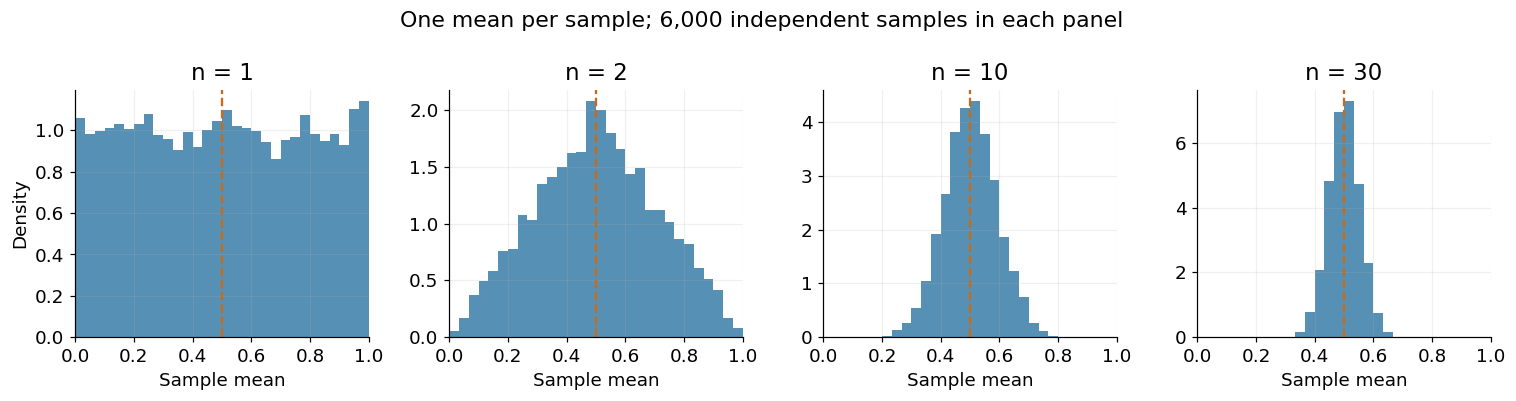

In [8]:
# PowerPoint: Slide 11 (cell 1/2) — Sampling distributions and their spread
# After this demonstration: return to Slide 12.
sampling_sizes = [1, 2, 10, 30]
N_SAMPLES = 6_000  # Number of complete samples, for each chosen n.
rng_sampling = np.random.default_rng(60)
uniform_means = {}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.7), sharex=True)
for ax, n in zip(axes, sampling_sizes):
    draws = rng_sampling.uniform(0, 1, size=(N_SAMPLES, n))
    means = draws.mean(axis=1)
    uniform_means[n] = means
    ax.hist(means, bins=np.linspace(0, 1, 31), density=True,
            color=BLUE, alpha=0.8)
    ax.axvline(0.5, color=ORANGE, linestyle="--")
    ax.set(title=f"n = {n}", xlabel="Sample mean", xlim=(0, 1))
axes[0].set_ylabel("Density")
fig.suptitle(f"One mean per sample; {N_SAMPLES:,} independent samples in each panel")
fig.tight_layout()
plt.show()

### The centre and spread can be derived exactly

Let the observations be i.i.d. with mean $\mu$ and variance $\sigma^2$.
Using the expectation and independent-sum rules from earlier SMP sessions:

$$E[\bar X_n]=\frac1n\sum_{j=1}^n E[X_j]=\mu,$$

$$\operatorname{Var}(\bar X_n)
=\frac1{n^2}\sum_{j=1}^n\operatorname{Var}(X_j)
=\frac{\sigma^2}{n}.$$

The standard deviation is $\sigma/\sqrt n$. These moment formulas do **not** require
normal observations or the CLT. Independence is needed for adding the variances.

In the histograms, **density** means that area represents relative frequency;
heights need not be below 1. The y-axis scales differ so each panel remains readable.
Compare the **horizontal spread**, using the same x-axis in all four panels.

<a id="ppt-slide-11-part-2"></a>

**PowerPoint: Slide 11 (cell 2/2) · Optional.** Sampling distributions and their spread. Return to **Slide 12** after the demonstration. [Slide index](#powerpoint-index).


In [9]:
# PowerPoint: Slide 11 (cell 2/2) — Sampling distributions and their spread
# Uses: Slide 11, cell 1 (run the earlier labelled cells first).
# After this demonstration: return to Slide 12.
display(pd.DataFrame([
    {"n": n, "Simulated mean": uniform_means[n].mean(),
     "Theoretical mean": 0.5,
     "Simulated SD of means": uniform_means[n].std(ddof=0),
     "Theoretical SD of means": np.sqrt(1 / (12 * n))}
    for n in sampling_sizes
]).set_index("n"))

,Simulated mean,Theoretical mean,Simulated SD of means,Theoretical SD of means
n,,,,
1,0.49985,0.5,0.29109,0.28868
2,0.50201,0.5,0.20584,0.20412
10,0.50277,0.5,0.09120,0.09129
30,0.50050,0.5,0.05293,0.05270


## Slide 12: The general Monte Carlo method

Monte Carlo means using random samples to estimate a numerical quantity.
One complete trial produces a recorded output $Y$; its expected value is the target:

$$\theta=E[Y],\qquad
\widehat\theta_N=\frac1N\sum_{i=1}^N Y_i.$$

The **estimator** is this rule. An **estimate** is the numerical result of applying
it to one set of simulations. The outputs can be workloads, costs, transformed
measurements, or 0/1 answers to an event.

1. Specify the probability model.
2. Simulate one complete trial.
3. Record the output that answers the question.
4. Repeat independently and average.

We will add a fifth step, **report numerical uncertainty**, after learning why
averaging works and how its variation behaves.


## Slide 13: Indicators turn probabilities into expectations

Define an **indicator** for morning $i$:

$$I_i=\begin{cases}1,&S_{50}^{(i)}\le110,\\0,&S_{50}^{(i)}>110.\end{cases}$$

The superscript $(i)$ labels a morning; it is **not a power**. If
$p=P(S_{50}\le110)$, then

$$E[I_i]=1p+0(1-p)=p.$$

In Python, `True` behaves like 1 and `False` like 0 when averaged. Thus

$$\underbrace{\frac1N\sum_{i=1}^N S_{50}^{(i)}}_{\text{average items}}
\quad\text{and}\quad
\underbrace{\widehat p_N=\frac1N\sum_{i=1}^N I_i
=\frac{\text{mornings within capacity}}{N}}_{\text{estimated probability}}
$$

answer **different questions**. The hat in $\widehat p_N$ indicates an estimate
computed from random simulated data. It changes between runs; the model's $p$ does not.


## Slide 14: Simulating many mornings

We will keep two counts separate throughout:

| Symbol | Meaning in this example | What changes if it increases? |
|:--|:--|:--|
| $n$ | Orders **inside one morning**, here 50 | The workload distribution and the question |
| $N$ | Complete mornings simulated | Numerical precision for the **same** question |

Generate an array with $N$ rows and $n$ columns. Each row is one morning. Each
entry is one order's item count. `sum(axis=1)` adds across each row.

**Predict:** as we simulate more mornings, what should the average workload
approach? What different calculation would answer the capacity question?

<a id="ppt-slide-14"></a>

**PowerPoint: Slide 14.** Simulating many mornings. Revisit this cell from Slide 16 to change the seed. Restore seed 6 and rerun this cell before continuing to Slide 17. The seed-6 output matches the fixed results in the deck. Return to **Slide 15** after the demonstration. [Slide index](#powerpoint-index).


In [38]:
# PowerPoint: Slide 14 — Simulating many mornings
# Uses: Slide 4 model setup (run the earlier labelled cells first).
# Also Slide 16: change the seed, then restore 6 and rerun before continuing.
# After this demonstration: return to Slide 15.
N_WAREHOUSE = 100_000
rng_warehouse = np.random.default_rng()
warehouse_orders = rng_warehouse.choice(
    ORDER_VALUES, size=(N_WAREHOUSE, ORDERS_PER_MORNING), p=ORDER_PROBS
)
workloads = warehouse_orders.sum(axis=1)       # One total for each morning.
within_capacity = workloads <= CAPACITY      # One True/False for each morning.

display(pd.DataFrame(warehouse_orders[:5, :8],
                     columns=[f"Order {j}" for j in range(1, 9)])
        .rename_axis("Morning index (first 8 orders only)"))
print(f"Full array: {warehouse_orders.shape[0]:,} mornings × "
      f"{warehouse_orders.shape[1]} orders")
print(f"Average workload: {workloads.mean():.4f} items")
print(f"Fraction within capacity: {within_capacity.mean():.5f} "
      f"= {within_capacity.mean():.3%}")

,Order 1,Order 2,Order 3,Order 4,Order 5,Order 6,Order 7,Order 8
Morning index (first 8 orders only),,,,,,,,
0,1,1,2,1,2,2,1,1
1,1,1,1,2,1,1,1,1
2,1,1,1,1,1,1,6,2
3,2,6,2,1,1,2,1,1
4,1,1,1,1,1,2,2,1


Full array: 100,000 mornings × 50 orders
Average workload: 89.9759 items
Fraction within capacity: 0.96812 = 96.812%


## Slide 15: Reading the simulation results

Inspect the workload and indicator for each morning, then compare the estimates as the number of mornings grows.

<a id="ppt-slide-15"></a>

**PowerPoint: Slide 15.** Reading the simulation results. Return to **Slide 16** after the demonstration. [Slide index](#powerpoint-index).


In [10]:
# PowerPoint: Slide 15 — Reading the simulation results
# Uses: Slide 14 (run the earlier labelled cells first).
# After this demonstration: return to Slide 16.
# Inspect the two outputs side by side.
display(pd.DataFrame({
    "Workload S": workloads[:12],
    "Within capacity?": within_capacity[:12],
    "Indicator I": within_capacity[:12].astype(int),
}))

checkpoint_rows = []
for N in [100, 1_000, 10_000, 100_000]:
    checkpoint_rows.append({"Mornings N": N,
                            "Average items": workloads[:N].mean(),
                            "Fraction within capacity": within_capacity[:N].mean()})
display(pd.DataFrame(checkpoint_rows).set_index("Mornings N"))

,Workload S,Within capacity?,Indicator I
0,82,True,1
1,102,True,1
2,96,True,1
3,85,True,1
4,90,True,1
5,84,True,1
6,87,True,1
7,81,True,1
8,109,True,1
9,103,True,1


,Average items,Fraction within capacity
Mornings N,,
100,88.9700,0.97000
1000,89.6100,0.97800
10000,90.0900,0.96860
100000,89.9787,0.96818


### Reading the results

All rows use the **same first 100,000 simulated mornings**. The smaller rows are
prefixes of that sequence, not separate experiments. The workload average is near
90; the fraction fitting is near 0.968. The second number is **not** another version
of the average workload.

**Discussion:** why near 0.968 rather than 0.93? The probabilities of order sizes,
50 orders per morning, their independence, and capacity 110 together determine the
answer. The random-number generator samples from that model. It does not choose the
target probability, and we have not assumed a normal workload distribution.

The model has a fixed probability even if we cannot calculate it neatly by hand.
The [optional benchmark at Slide 23B](#ppt-slide-23b) calculates it directly for this small model.

## Slide 16: The seed experiment

The PowerPoint cue deliberately reuses the [Slide 14 simulation cell](#ppt-slide-14). If you try a different seed, restore seed 6 and rerun that cell afterwards. Then return to Slide 17 and continue down to the LLN demonstration below. This optional repeat does not change the order of the teaching cells.


## Slide 18: The law of large numbers

Repeat the same experiment independently and average its outputs. As the number
of trials grows, it becomes unlikely that the average is far from the expected output.
This is the **law of large numbers (LLN)**.

For i.i.d. outputs with finite $E[|Y|]$,

$$\frac1N\sum_{i=1}^N Y_i\xrightarrow{P}E[Y].$$

The arrow means **convergence in probability**: for any chosen tolerance
$\varepsilon>0$, $P(|\widehat\theta_N-E[Y]|>\varepsilon)$ tends to zero as $N$ grows.
Finite $E[|Y|]$ ensures a finite target. It holds for the bounded warehouse outputs.

Apply the same statement to two different outputs: workload and a capacity indicator.

**Predict:** will the running average get closer to its target after *every* new morning?

<a id="ppt-slide-18"></a>

**PowerPoint: Slide 18.** LLN: two running averages. Return to **Slide 19** after the demonstration. [Slide index](#powerpoint-index).


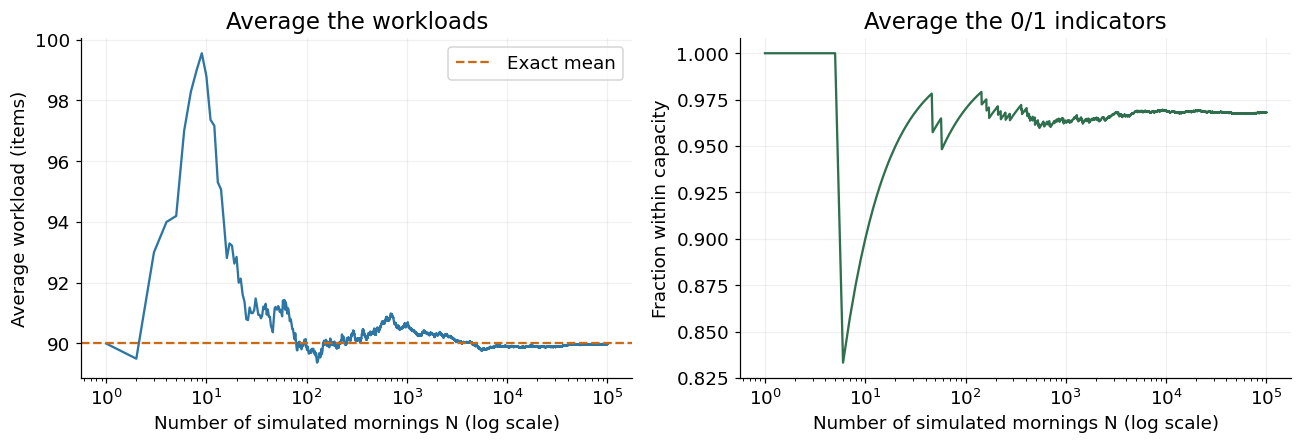

In [40]:
# PowerPoint: Slide 18 — LLN: two running averages
# Uses: Slide 14 (run the earlier labelled cells first).
# After this demonstration: return to Slide 19.
trial_counts = np.arange(1, N_WAREHOUSE + 1)
running_workload = np.cumsum(workloads) / trial_counts
running_probability = np.cumsum(within_capacity) / trial_counts
expected_workload = ORDERS_PER_MORNING * np.dot(ORDER_VALUES, ORDER_PROBS)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(trial_counts, running_workload, color=BLUE)
axes[0].axhline(expected_workload, color=ORANGE, linestyle="--", label="Exact mean")
axes[0].set(ylabel="Average workload (items)", title="Average the workloads")
axes[0].legend()
axes[1].plot(trial_counts, running_probability, color=GREEN)
axes[1].set(ylabel="Fraction within capacity", title="Average the 0/1 indicators")
for ax in axes:
    ax.set_xscale("log")
    ax.set_xlabel("Number of simulated mornings N (log scale)")
fig.tight_layout()
plt.show()

### What the LLN does and does not promise

The paths wobble. A single finite run can move away from its target before moving
back. On the logarithmic x-axis, equal horizontal steps represent multiplication
of $N$ by 10, not addition of the same number of mornings.
The early fraction can be 1 when all of the first few mornings happen to fit;
that does not make 1 the model's target probability.

The LLN describes **averages over more mornings**. An individual future morning
does not become less variable because we ran more simulations. It also does not
give an error bar for a particular $N$; that needs more information.

**Live question:** would a new seed change where the two averages settle, or just
the paths they take? The optional Slide 18B example below repeats this experiment over 100 paths rather
than relying on the appearance of one path.

## Slide 18B: Optional Bernoulli LLN paths (Exercise 6)

For $I_1,I_2,\ldots\sim\operatorname{Bernoulli}(0.3)$, each running mean estimates 0.3. The LLN says that, for a large fixed $n$, repeated paths have averages concentrated near 0.3; it does **not** say that one realised path moves monotonically.

**Predict.** For 100 paths, compare $n=10,100,1{,}000,10{,}000$. What becomes smaller: individual 0/1 outcomes, or the variation of averages? Will every final mean equal 0.3?

<a id="ppt-slide-18b"></a>

**PowerPoint: Slide 18B (cell 1/2) · Optional.** Optional LLN extension: several Bernoulli paths. An alternative to the warehouse plot. Run both labelled cells. This is a notebook extension of Slide 18, not an extra slide. [Next cell for this slide](#ppt-slide-18b-part-2). Return to **Slide 19** after the demonstration. [Slide index](#powerpoint-index).


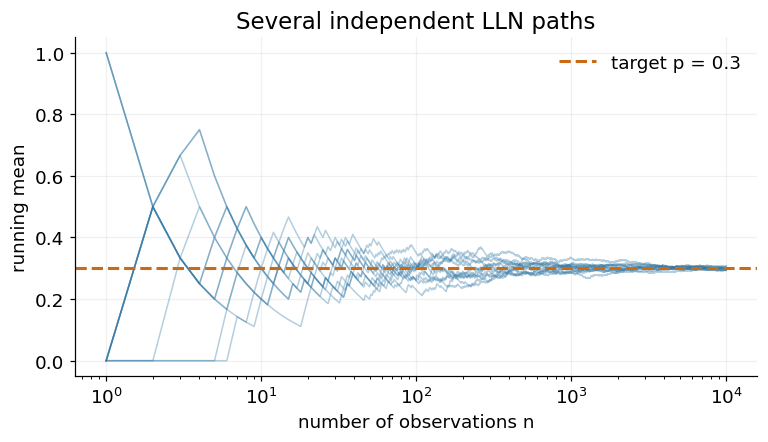

In [13]:
# PowerPoint: Slide 18B (cell 1/2) — Optional LLN extension: several Bernoulli paths
# After this demonstration: return to Slide 19.
# Editable parameters
bern_p, bern_paths, bern_length, bern_tolerance = 0.30, 100, 10_000, 0.02
bern_check_ns = [10, 100, 1_000, 10_000]
bern_rng = np.random.default_rng(2406)
bern_draws = bern_rng.binomial(1, bern_p, size=(bern_paths, bern_length))
bern_running = np.cumsum(bern_draws, axis=1)/np.arange(1, bern_length+1)
bern_endpoints = bern_running[:, -1]
fig, ax = plt.subplots(figsize=(8, 4))
for bern_path in bern_running[:12]:
    ax.plot(np.arange(1, bern_length+1), bern_path, color=BLUE, alpha=.35, lw=1)
ax.axhline(bern_p, color=ORANGE, ls="--", lw=2, label=f"target p = {bern_p}")
ax.set(xscale="log", xlabel="number of observations n", ylabel="running mean", title="Several independent LLN paths")
ax.legend(frameon=False); plt.show()

<a id="ppt-slide-18b-part-2"></a>

**PowerPoint: Slide 18B (cell 2/2) · Optional.** Optional LLN extension: several Bernoulli paths. Return to **Slide 19** after the demonstration. [Slide index](#powerpoint-index).


In [14]:
# PowerPoint: Slide 18B (cell 2/2) — Optional LLN extension: several Bernoulli paths
# Uses: Slide 18B, cell 1 (run the earlier labelled cells first).
# After this demonstration: return to Slide 19.
# Exact decimal fractions keep strict boundary comparisons correct.
from fractions import Fraction
from math import ceil, floor
bern_p_exact = Fraction(str(bern_p))
bern_tol_exact = Fraction(str(bern_tolerance))
bern_rows = []
for bern_n in bern_check_ns:
    bern_counts_at_n = bern_draws[:, :bern_n].sum(axis=1)
    bern_means_at_n = bern_counts_at_n/bern_n
    # count/n < p-tol iff count <= ceil(n(p-tol))-1;
    # count/n > p+tol iff count >= floor(n(p+tol))+1.
    bern_low_max = ceil(bern_n*(bern_p_exact-bern_tol_exact)) - 1
    bern_high_min = floor(bern_n*(bern_p_exact+bern_tol_exact)) + 1
    bern_far = ((bern_counts_at_n <= bern_low_max)
                | (bern_counts_at_n >= bern_high_min))
    bern_rows.append((bern_n, bern_means_at_n.mean(), bern_means_at_n.std(ddof=1),
                      np.sqrt(bern_p*(1-bern_p)/bern_n), bern_far.mean(), bern_far.sum()))
bern_table = pd.DataFrame(bern_rows, columns=[
    "n", "empirical mean", "empirical SD", "theory SD",
    "estimated P(|mean-p| > tolerance)", "paths beyond tolerance"])
display(bern_table.style.format({"empirical mean": "{:.4f}", "empirical SD": "{:.4f}",
                                  "theory SD": "{:.4f}",
                                  "estimated P(|mean-p| > tolerance)": "{:.2f}"}))
print(f"Tolerance = {bern_tolerance}; each probability estimate uses only {bern_paths} paths, so it is coarse.")

,n,empirical mean,empirical SD,theory SD,estimated P(|mean-p| > tolerance),paths beyond tolerance
0,10,0.2820,0.1359,0.1449,0.74,74
1,100,0.2981,0.0454,0.0458,0.57,57
2,1000,0.2992,0.0144,0.0145,0.17,17
3,10000,0.3000,0.0042,0.0046,0.00,0


Tolerance = 0.02; each probability estimate uses only 100 paths, so it is coarse.


## Slide 20: The central limit theorem

The LLN tells us that an average concentrates near its target. The **central limit
theorem (CLT)** describes its approximate distribution around that target.

For i.i.d. observations with finite mean $\mu$ and finite **positive** variance
$\sigma^2$, the standardised sample mean approaches a standard normal distribution:

$$Z_n=\frac{\bar X_n-\mu}{\sigma/\sqrt n}
\xrightarrow{d}\mathcal N(0,1).$$

Standardising means subtracting the mean and dividing by the standard deviation.
The arrow $\xrightarrow d$ concerns the **distribution**, not the numerical value
of an individual sample mean. We write $\mathcal N(a,b)$ with $b$ as the **variance**.

Equivalently, for a sufficiently accurate large-$n$ approximation,

$$\bar X_n\ \mathrel{\dot\sim}\ \mathcal N\!\left(\mu,\frac{\sigma^2}{n}\right),$$

where $\dot\sim$ means “is approximately distributed as.”

**Predict:** after standardising, should the histograms have different centres and
spreads, or mainly different shapes?

<a id="ppt-slide-20"></a>

**PowerPoint: Slide 20 (cell 1/2).** CLT: standardised means. The first cell visualises the CLT. The second is an optional probability calculation for the mean of 30 uniform draws. [Next cell for this slide](#ppt-slide-20-part-2). Return to **Slide 21** after the demonstration. [Slide index](#powerpoint-index).


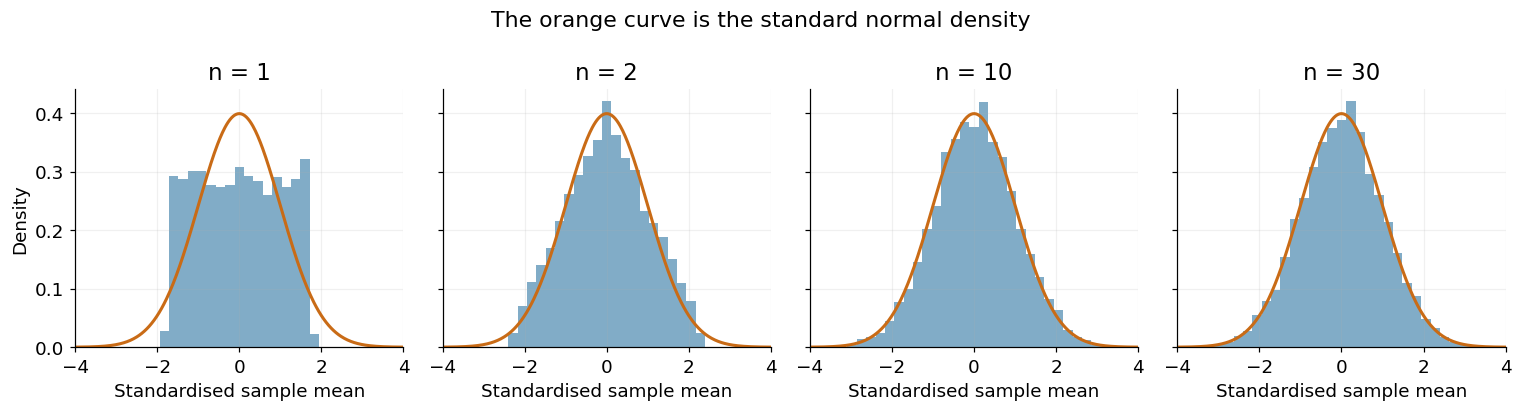

In [15]:
# PowerPoint: Slide 20 (cell 1/2) — CLT: standardised means
# Uses: Slide 11, cell 1 (run the earlier labelled cells first).
# After this demonstration: return to Slide 21.
z_grid = np.linspace(-4, 4, 400)
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8), sharex=True, sharey=True)
for ax, n in zip(axes, sampling_sizes):
    standardised = (uniform_means[n] - 0.5) / np.sqrt(1 / (12 * n))
    ax.hist(standardised, bins=np.linspace(-4, 4, 36), density=True,
            color=BLUE, alpha=0.6)
    ax.plot(z_grid, stats.norm.pdf(z_grid), color=ORANGE, linewidth=2)
    ax.set(title=f"n = {n}", xlabel="Standardised sample mean", xlim=(-4, 4))
axes[0].set_ylabel("Density")
fig.suptitle("The orange curve is the standard normal density")
fig.tight_layout()
plt.show()

### A probability calculation after introducing the CLT

For 30 independent uniform observations,

$$P(0.45<\bar X_{30}<0.55)
\approx\Phi\!\left(\frac{0.55-0.5}{\sqrt{1/(12\cdot30)}}\right)
-\Phi\!\left(\frac{0.45-0.5}{\sqrt{1/(12\cdot30)}}\right).$$

Here $\Phi(z)=P(Z\le z)$ for a standard normal $Z$; this is the standardisation
method from SMP 4. In code, `stats.norm.cdf` calculates $\Phi$.

**Predict:** should the Monte Carlo fraction equal the approximation exactly?

<a id="ppt-slide-20-part-2"></a>

**PowerPoint: Slide 20 (cell 2/2).** CLT: standardised means. Return to **Slide 21** after the demonstration. [Slide index](#powerpoint-index).


In [16]:
# PowerPoint: Slide 20 (cell 2/2) — CLT: standardised means
# Uses: Slide 11, cell 1 (run the earlier labelled cells first).
# After this demonstration: return to Slide 21.
n_uniform_probability = 30
uniform_se = np.sqrt(1 / (12 * n_uniform_probability))
uniform_clt_probability = (
    stats.norm.cdf((0.55 - 0.5) / uniform_se)
    - stats.norm.cdf((0.45 - 0.5) / uniform_se)
)
uniform_sim_probability = ((uniform_means[30] > 0.45)
                           & (uniform_means[30] < 0.55)).mean()
display(pd.DataFrame({"Method": ["CLT approximation", "Monte Carlo (6,000 samples)"],
                      "Probability": [uniform_clt_probability, uniform_sim_probability]}))

,Method,Probability
0,CLT approximation,0.65722
1,"Monte Carlo (6,000 samples)",0.65050


There are two potential differences: the normal approximation is not exact, and
the Monte Carlo answer has random numerical error. More simulated samples reduce
the latter; they do not repair a poor normal approximation.

There is **no universal rule that $n=30$ is enough**. Accuracy depends on the
population and the probability being calculated, particularly in a tail.
For independent normal observations, the sample mean is **exactly** normal for
every $n$. The examples at Slides 41A and 21 contrast the exact-normal and skewed cases.

This section also provides a live model for website Exercise 7.

## Slide 21: Optional skewed-population example
### Website Exercise 2

The stated population mean and SD are 19.86 and 23.65. They give exact standard
errors $23.65/\sqrt n$, but **do not specify the population distribution**.

For a concrete illustration, choose a synthetic population with counts 0, 20 and
80, with probabilities approximately 0.354839, 0.529215 and 0.115946. This is a
right-skewed count model matching those two moments. It is **one possible model**,
not a claim about the actual tree-count distribution. No new distribution family
is needed to simulate it.

**Predict:** why might a normal approximation to the mean of eight such counts
be questionable? Would increasing the number of simulated samples change that
underlying sampling distribution?

<a id="ppt-slide-21"></a>

**PowerPoint: Slide 21 · Optional.** Optional CLT extension: a skewed population. Show the histograms. The three-point population is illustrative, not inferred uniquely from its mean and SD. The probability-solving code is instructor background. Return to **Slide 22** after the demonstration. [Slide index](#powerpoint-index).


,Tree count,Illustrative probability
0,0,0.35484
1,20,0.52921
2,80,0.11595


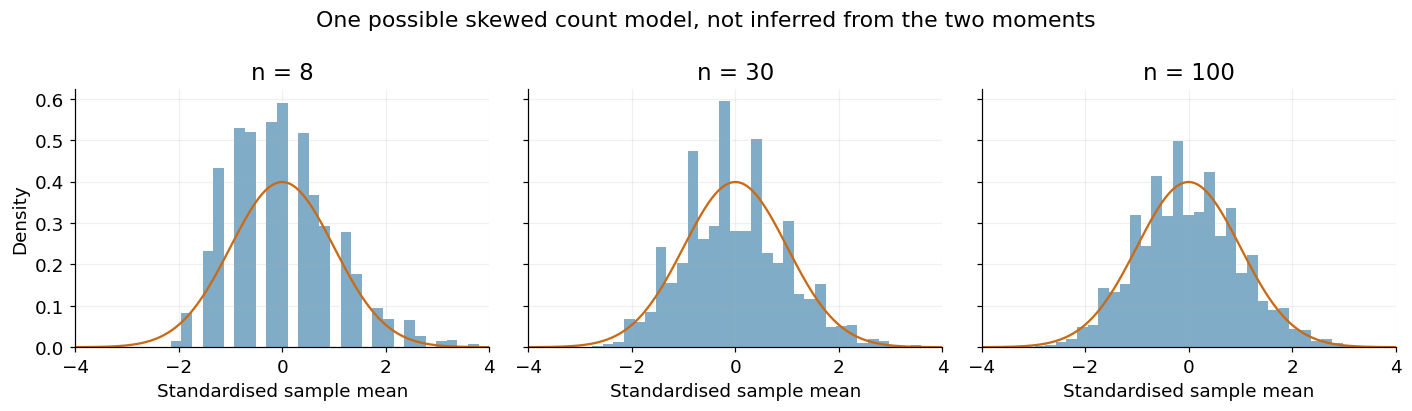

,Theoretical SE,Simulated SD of means
n,,
8,8.36154,8.48884
30,4.31788,4.36414
100,2.36500,2.34658


In [17]:
# PowerPoint: Slide 21 — Optional CLT extension: a skewed population
# After this demonstration: return to Slide 22.
tree_mean, tree_sd = 19.86, 23.65
tree_values = np.array([0, 20, 80])
# Solve for probabilities matching total probability, E[X], and E[X²].
tree_matrix = np.vstack([np.ones(3), tree_values, tree_values ** 2])
tree_probs = np.linalg.solve(tree_matrix, [1, tree_mean, tree_mean ** 2 + tree_sd ** 2])
display(pd.DataFrame({"Tree count": tree_values, "Illustrative probability": tree_probs}))

tree_sizes, tree_repetitions = [8, 30, 100], 10_000
rng_tree = np.random.default_rng(71)
tree_rows = []
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True, sharey=True)
for ax, n in zip(axes, tree_sizes):
    tree_means = rng_tree.choice(tree_values, size=(tree_repetitions, n),
                                p=tree_probs).mean(axis=1)
    tree_se = tree_sd / np.sqrt(n)
    tree_z = (tree_means - tree_mean) / tree_se
    ax.hist(tree_z, bins=np.linspace(-4, 4, 40), density=True, alpha=0.6, color=BLUE)
    tree_grid = np.linspace(-4, 4, 400)
    ax.plot(tree_grid, stats.norm.pdf(tree_grid), color=ORANGE)
    ax.set(title=f"n = {n}", xlabel="Standardised sample mean", xlim=(-4, 4))
    tree_rows.append({"n": n, "Theoretical SE": tree_se,
                       "Simulated SD of means": tree_means.std(ddof=1)})
axes[0].set_ylabel("Density")
fig.suptitle("One possible skewed count model, not inferred from the two moments")
fig.tight_layout()
plt.show()
display(pd.DataFrame(tree_rows).set_index("n"))

The distribution is discrete, so small-sample means sit on a visible grid.
Skewness and discreteness can make a small-sample normal approximation poor.
Larger $n$ improves the approximation here, but there is no universal cutoff.
More outer repetitions produce a clearer picture of each distribution, not a
different distribution.

The linear solve in the code merely constructs the illustrative probabilities
by matching the three stated equations; it is not a new Monte Carlo method or a
student prerequisite. The mathematical SE calculation uses the supplied SD 23.65.

<a id="sums"></a>
## Slide 23: From a sample mean to a total

The warehouse asks about a **sum**, not a mean of orders. Since
$S_n=X_1+\cdots+X_n=n\bar X_n$,

$$E[S_n]=n\mu,\qquad \operatorname{Var}(S_n)=n\sigma^2,$$

$$\frac{S_n-n\mu}{\sigma\sqrt n}
=\frac{\bar X_n-\mu}{\sigma/\sqrt n}.$$

So the same CLT gives $S_n\mathrel{\dot\sim}\mathcal N(n\mu,n\sigma^2)$.
For the warehouse,

$$E[X^2]=0.60(1^2)+0.30(2^2)+0.10(6^2)=5.4,$$
$$\operatorname{Var}(X)=5.4-1.8^2=2.16,\quad
E[S_{50}]=90,\quad\operatorname{Var}(S_{50})=108.$$

**Predict:** capacity 110 is roughly how many standard deviations above the mean?

<a id="ppt-slide-23"></a>

**PowerPoint: Slide 23 · Optional.** Warehouse probability: normal approximation and simulation. Return to **Slide 24** after the demonstration. [Slide index](#powerpoint-index).


Total mean = 90.00; total SD = 10.3923
Capacity is 1.9245 SDs above the mean
Normal approximation: 0.97285
Monte Carlo estimate: 0.96818


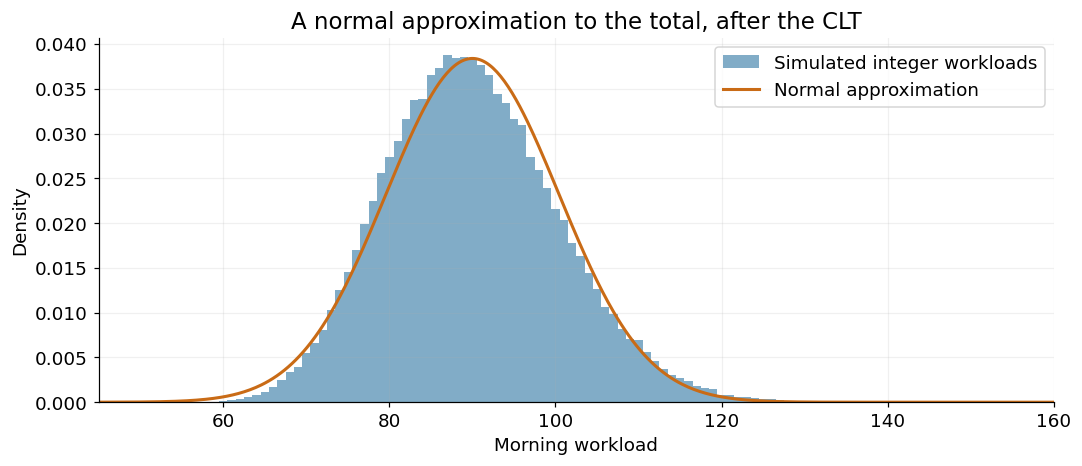

In [18]:
# PowerPoint: Slide 23 — Warehouse probability: normal approximation and simulation
# Uses: Slide 14 (run the earlier labelled cells first).
# After this demonstration: return to Slide 24.
order_mean = np.dot(ORDER_VALUES, ORDER_PROBS)
order_variance = np.dot(ORDER_VALUES ** 2, ORDER_PROBS) - order_mean ** 2
total_mean = ORDERS_PER_MORNING * order_mean
total_sd = np.sqrt(ORDERS_PER_MORNING * order_variance)
warehouse_z = (CAPACITY - total_mean) / total_sd
warehouse_normal_probability = stats.norm.cdf(warehouse_z)
print(f"Total mean = {total_mean:.2f}; total SD = {total_sd:.4f}")
print(f"Capacity is {warehouse_z:.4f} SDs above the mean")
print(f"Normal approximation: {warehouse_normal_probability:.5f}")
print(f"Monte Carlo estimate: {within_capacity.mean():.5f}")

fig, ax = plt.subplots()
ax.hist(workloads, bins=np.arange(49.5, 160.5), density=True,
        alpha=0.6, color=BLUE, label="Simulated integer workloads")
grid = np.linspace(45, 160, 500)
ax.plot(grid, stats.norm.pdf(grid, loc=total_mean, scale=total_sd),
        color=ORANGE, linewidth=2, label="Normal approximation")
ax.set(xlabel="Morning workload", ylabel="Density", xlim=(45, 160),
       title="A normal approximation to the total, after the CLT")
ax.legend()
fig.tight_layout()
plt.show()

The simulation sampled the original discrete order model. It did **not** generate
normal workloads. The normal calculation is a different method: an approximation
to the distribution of their sum.

Note the software convention: `stats.norm(..., scale=...)` takes a **standard
deviation**, whereas the second entry of our written $\mathcal N(\mu,\sigma^2)$
notation is a **variance**.

**Continuity correction, when needed:** integer $S\le k$ includes the whole bin
centred at $k$. Its continuous boundary is $k+0.5$. The Slide 24 example explains this
before applying it to annual accident counts. A half-unit correction fixes a
boundary mismatch, not every difference in shape; it need not improve every
normal approximation for a skewed distribution.

## Slide 23B: Optional direct warehouse benchmark

This small discrete model is simple enough to compute the total's probability
distribution numerically, without random sampling. This is **optional instructor
material**, not a new examinable method.

Start with probability 1 at total 0. To add an order, move each current total up
by 1, 2 or 6 and multiply by that order's probability. Add contributions that lead
to the same new total. Repeat for 50 orders. NumPy's `convolve` performs exactly
this probability-table update for independent sums.

**Predict:** should changing a random seed affect this calculation?

<a id="ppt-slide-23b"></a>

**PowerPoint: Slide 23B · Optional.** Instructor extension: a direct warehouse benchmark. Optional instructor check. Convolution is outside the required teaching sequence. This is an extension of Slide 23, not an extra slide. Return to **Slide 24** after the demonstration. [Slide index](#powerpoint-index).


In [19]:
# PowerPoint: Slide 23B — Instructor extension: a direct warehouse benchmark
# After this demonstration: return to Slide 24.
# Self-contained baseline benchmark; intentionally no random generator.
benchmark_order_pmf = np.zeros(7)
benchmark_order_pmf[[1, 2, 6]] = [0.60, 0.30, 0.10]
benchmark_total_pmf = np.array([1.0])
for _ in range(50):
    benchmark_total_pmf = np.convolve(benchmark_total_pmf, benchmark_order_pmf)
benchmark_p = benchmark_total_pmf[:111].sum()  # Include totals 0 through 110.
benchmark_mean = np.dot(np.arange(len(benchmark_total_pmf)), benchmark_total_pmf)
print(f"Total probability: {benchmark_total_pmf.sum():.12f}")
print(f"Mean workload: {benchmark_mean:.8f}")
print(f"Direct P(S₅₀ ≤ 110): {benchmark_p:.10f}")
print("Exact model calculation up to floating-point rounding; no Monte Carlo noise.")

Total probability: 1.000000000000
Mean workload: 90.00000000
Direct P(S₅₀ ≤ 110): 0.9679212970
Exact model calculation up to floating-point rounding; no Monte Carlo noise.


The benchmark is about **0.9679213**. That is why repeated Monte Carlo answers
cluster near 96.8% under this particular model. They would cluster elsewhere if
the order probabilities, order count, independence assumption or capacity changed.

The simple normal approximation is about 0.97285. This difference is an
approximation error, not a problem with the random-number generator. The benchmark
is available here because the model is small; Monte Carlo becomes especially
useful when a direct calculation is difficult.

## Slide 24: Annual accident counts and continuity correction (Exercise 3)

Let $X_d$ be the count on day $d$, with independent $X_d\sim\operatorname{Poisson}(10)$. For $S=\sum_{d=1}^{365}X_d$,
$$E[S]=365(10)=3650,\qquad\operatorname{Var}(S)=365(10)=3650.$$
For $P(S>3800)$, the integer event is $S\geq3801$, so a normal approximation uses 3800.5. The bin centred at 3801 starts at 3800.5. In SciPy, `norm.sf(t, loc=mean, scale=sd)` returns the upper-tail probability $P(W>t)$ of that normal variable.

**Predict.** Is the continuity-corrected normal answer larger or smaller than the uncorrected approximation using 3800? Which boundary better matches the discrete event?

<a id="ppt-slide-24"></a>

**PowerPoint: Slide 24 · Optional.** Normal approximation to an annual count. Use only this approximation cell here. The daily simulation and its Monte Carlo SE are labelled Slide 41B, after SE has been introduced. Return to **Slide 25** after the demonstration. [Slide index](#powerpoint-index).


In [20]:
# PowerPoint: Slide 24 — Normal approximation to an annual count
# After this demonstration: return to Slide 25.
# Normal approximation: useful, but not exact
acc_days, acc_daily_mean, acc_cutoff = 365, 10, 3800
acc_mean = acc_variance = acc_days*acc_daily_mean
acc_sd = np.sqrt(acc_variance)
print(f"Without correction: {stats.norm.sf(acc_cutoff, acc_mean, acc_sd):.6f}")
print(f"With correction:    {stats.norm.sf(acc_cutoff+0.5, acc_mean, acc_sd):.6f}")

Without correction: 0.006517
With correction:    0.006368


## Slides 25–28: How accurate is a Monte Carlo estimate?

One morning may have a very different workload from another. That is **variation
in outputs**. Running a large simulation again gives a slightly different average.
That is **variation in estimates**.

Let $\sigma_Y=\operatorname{SD}(Y)$ denote the spread of one output. For an average
of $N$ i.i.d. outputs,

$$\operatorname{Var}(\widehat\theta_N)=\frac{\sigma_Y^2}{N},\qquad
\operatorname{SE}(\widehat\theta_N)=\frac{\sigma_Y}{\sqrt N}.$$

The **standard error (SE)** is the standard deviation of the estimator over
repeated complete simulation runs. A Monte Carlo SE measures simulation precision
*within the chosen model*.

**Predict:** if we use four times as many trials, by what factor does the SE change?

### Estimating an unknown output standard deviation

When $\sigma_Y$ is unknown, use the simulated outputs to calculate

$$s_Y^2=\frac1{N-1}\sum_{i=1}^N(Y_i-\widehat\theta_N)^2,
\qquad \widehat{\operatorname{SE}}(\widehat\theta_N)=\frac{s_Y}{\sqrt N}.$$

$s_Y$ is the sample standard deviation of individual outputs. Their deviations
from their own mean sum to zero, so only $N-1$ can vary freely. Dividing by $N-1$
corrects the downward bias in this variance estimate. In NumPy,
`std(ddof=1)` uses this divisor, then takes the square root.

For a 0/1 indicator, $I^2=I$, so

$$\operatorname{Var}(I)=E[I^2]-E[I]^2=p-p^2=p(1-p).$$

Hence a convenient plug-in formula is

$$\widehat{\operatorname{SE}}(\widehat p_N)
=\sqrt{\frac{\widehat p_N(1-\widehat p_N)}{N}}.$$

This plug-in formula and `std(ddof=1)/sqrt(N)` differ by a factor
$\sqrt{N/(N-1)}$. They are essentially identical for large $N$; neither should
be mistaken for an exact error bound.

<a id="ppt-slide-28"></a>

**PowerPoint: Slide 28 (cell 1/2).** Monte Carlo standard errors. The first cell reports both warehouse SEs. The second is an optional repeated-run demonstration that prepares the coverage plot at Slide 30. [Next cell for this slide](#ppt-slide-28-part-2). Return to **Slide 29** after the demonstration. [Slide index](#powerpoint-index).


In [21]:
# PowerPoint: Slide 28 (cell 1/2) — Monte Carlo standard errors
# Uses: Slide 14 (run the earlier labelled cells first).
# After this demonstration: return to Slide 29.
warehouse_mean_mcse = workloads.std(ddof=1) / np.sqrt(N_WAREHOUSE)
p_hat = within_capacity.mean()
warehouse_probability_mcse = np.sqrt(p_hat * (1 - p_hat) / N_WAREHOUSE)
display(pd.DataFrame({
    "Quantity": ["Mean workload (items)", "Probability within capacity"],
    "Estimate": [workloads.mean(), p_hat],
    "Estimated Monte Carlo SE": [warehouse_mean_mcse, warehouse_probability_mcse],
}))
print(f"SD of one workload: {workloads.std(ddof=1):.3f} items")
print(f"SE of the estimated mean workload: {warehouse_mean_mcse:.5f} items")

,Quantity,Estimate,Estimated Monte Carlo SE
0,Mean workload (items),89.97870,0.03284
1,Probability within capacity,0.96818,0.00056


SD of one workload: 10.386 items
SE of the estimated mean workload: 0.03284 items


### Seeing the standard error across repeated runs

Make 200 separate Monte Carlo estimates of the expected warehouse workload.
One recorded output is a complete morning's workload $Y=S_{50}$; the fixed target
is 90 items. Each estimate below averages its own set of simulated mornings.

**Predict:** will the scatter of 200 estimates be about the SD of $Y$, or about
that SD divided by the square root of the number of outputs in each run?

<a id="ppt-slide-28-part-2"></a>

**PowerPoint: Slide 28 (cell 2/2).** Monte Carlo standard errors. Return to **Slide 29** after the demonstration. [Slide index](#powerpoint-index).


SD across 200 estimates: 0.31674
Average estimated SE within runs: 0.32840


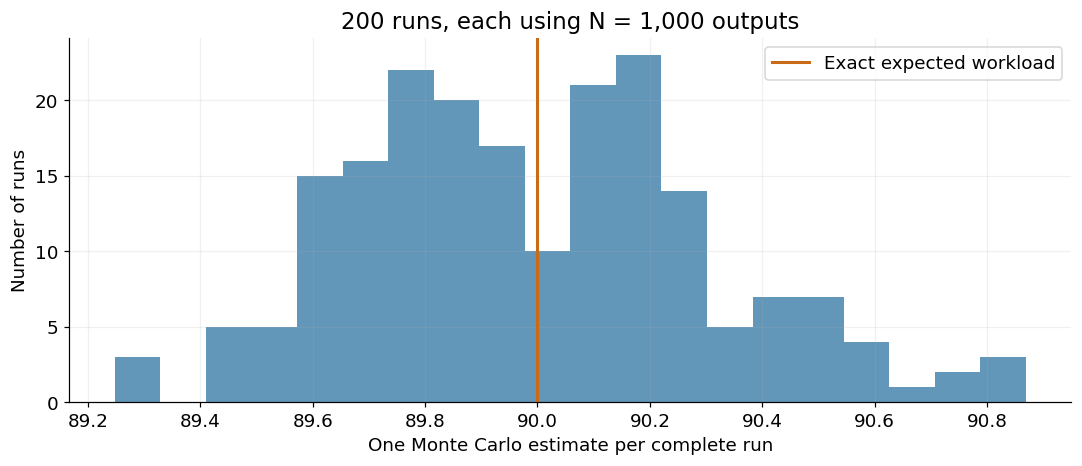

In [22]:
# PowerPoint: Slide 28 (cell 2/2) — Monte Carlo standard errors
# Uses: Slides 4 and 18 (run the earlier labelled cells first).
# After this demonstration: return to Slide 29.
REPEATED_RUNS = 200
TRIALS_PER_RUN = 1_000
rng_precision = np.random.default_rng(61)
precision_estimates = np.empty(REPEATED_RUNS)
precision_predicted_se = np.empty(REPEATED_RUNS)
for j in range(REPEATED_RUNS):
    precision_outputs = rng_precision.choice(
        ORDER_VALUES, size=(TRIALS_PER_RUN, ORDERS_PER_MORNING), p=ORDER_PROBS
    ).sum(axis=1)
    precision_estimates[j] = precision_outputs.mean()
    precision_predicted_se[j] = precision_outputs.std(ddof=1) / np.sqrt(TRIALS_PER_RUN)
print(f"SD across {REPEATED_RUNS} estimates: {precision_estimates.std(ddof=1):.5f}")
print(f"Average estimated SE within runs: {precision_predicted_se.mean():.5f}")
fig, ax = plt.subplots()
ax.hist(precision_estimates, bins=20, color=BLUE, alpha=0.75)
ax.axvline(expected_workload, color=ORANGE, linewidth=2, label="Exact expected workload")
ax.set(xlabel="One Monte Carlo estimate per complete run", ylabel="Number of runs",
       title=f"{REPEATED_RUNS} runs, each using N = {TRIALS_PER_RUN:,} outputs")
ax.legend()
fig.tight_layout()
plt.show()

## Slide 29: Why 1.96 appears in a 95% interval

The CLT applies to the Monte Carlo estimate because it is itself a sample mean.
When the normal approximation is adequate,

$$\frac{\widehat\theta_N-\theta}{\sigma_Y/\sqrt N}
\quad\text{is approximately standard normal}.$$

For $Z\sim\mathcal N(0,1)$, $P(-1.96\le Z\le1.96)\approx0.95$. Undoing the
standardisation gives approximately 95% probability that the random interval

$$\left[\widehat\theta_N-1.96\frac{\sigma_Y}{\sqrt N},\quad
\widehat\theta_N+1.96\frac{\sigma_Y}{\sqrt N}\right]$$

contains the fixed target $\theta$. In practice, replace $\sigma_Y$ by $s_Y$:

$$\boxed{\text{estimate}\ \pm\ 1.96\times\text{estimated SE}.}$$

This is an **approximate 95% confidence interval for the numerical target**.
It is not a prediction interval containing 95% of individual workloads.


## Slide 30: What 95% coverage means

Return to the 200 independent runs prepared in the second Slide 28 cell. Each run gives a different
estimate, a different SE and a different interval. We know the target 90 in
this teaching example, so we can check whether each interval contains it.

**Predict:** should exactly 95 of 100 intervals contain the target? What would a
red interval mean: an arithmetic mistake, or an expected possibility?

<a id="ppt-slide-30"></a>

**PowerPoint: Slide 30 · Optional.** What 95% coverage means. Uses the repeated runs prepared in the second Slide 28 cell (run that cell before this one). Each interval estimates the mean workload, not an individual morning. Return to **Slide 31** after the demonstration. [Slide index](#powerpoint-index).


Intervals containing the target: 191 / 200
Observed coverage: 95.5%


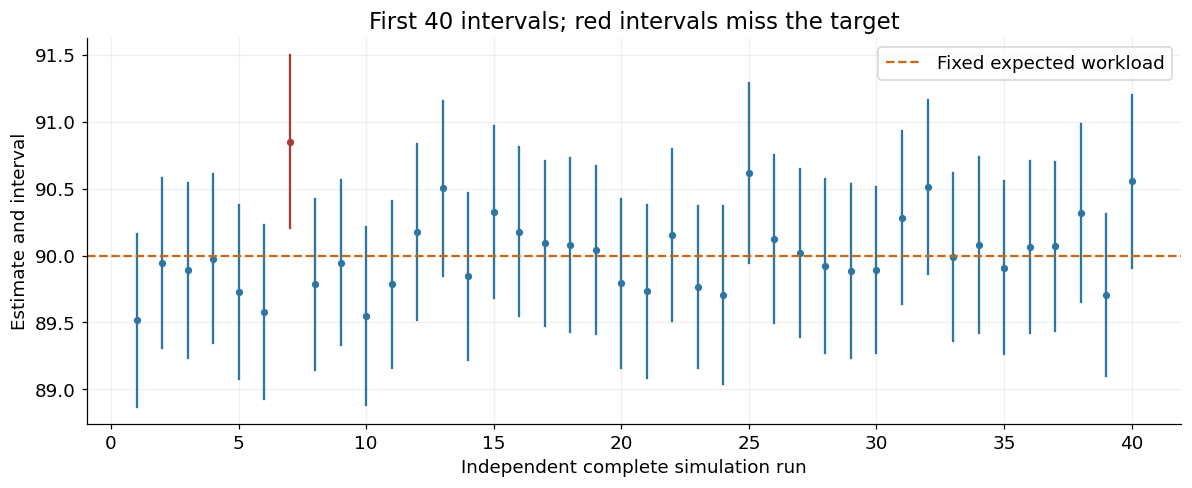

In [23]:
# PowerPoint: Slide 30 — What 95% coverage means
# Uses: Slide 28, cell 2 (which uses Slides 4 and 18) (run the earlier labelled cells first).
# After this demonstration: return to Slide 31.
precision_lower = precision_estimates - 1.96 * precision_predicted_se
precision_upper = precision_estimates + 1.96 * precision_predicted_se
precision_covers = ((precision_lower <= expected_workload)
                    & (expected_workload <= precision_upper))
print(f"Intervals containing the target: {precision_covers.sum()} / {REPEATED_RUNS}")
print(f"Observed coverage: {precision_covers.mean():.1%}")

SHOW_RUNS = 40
fig, ax = plt.subplots(figsize=(11, 4.6))
for j in range(SHOW_RUNS):
    colour = BLUE if precision_covers[j] else RED
    ax.plot([j + 1, j + 1], [precision_lower[j], precision_upper[j]], color=colour)
    ax.scatter(j + 1, precision_estimates[j], s=14, color=colour)
ax.axhline(expected_workload, color=ORANGE, linestyle="--", label="Fixed expected workload")
ax.set(xlabel="Independent complete simulation run", ylabel="Estimate and interval",
       title="First 40 intervals; red intervals miss the target")
ax.legend()
fig.tight_layout()
plt.show()

The target is fixed; the intervals vary. “95%” describes approximate long-run
coverage of the method, not a guarantee about every set of 100 runs. The observed
coverage above is itself a simulated proportion.

For a probability near 0 or 1, there must be enough simulated events **and**
non-events for this normal-interval method to work well. Zero hits do not justify
an interval of width zero. The Slide 38 example shows why rare events need special care.

## Slide 31: Reporting the warehouse probability

Use the estimate and estimated standard error from Slide 28 to report an approximate interval for the capacity probability.

<a id="ppt-slide-31"></a>

**PowerPoint: Slide 31 · Optional.** Reporting the warehouse probability and interval. Also checks the central normal probability used on Slide 29. Return to **Slide 32** after the demonstration. [Slide index](#powerpoint-index).


In [24]:
# PowerPoint: Slide 31 — Reporting the warehouse probability and interval
# Uses: Slide 28, cell 1 (run the earlier labelled cells first).
# After this demonstration: return to Slide 32.
normal_central_probability = stats.norm.cdf(1.96) - stats.norm.cdf(-1.96)
print(f"Standard normal probability between −1.96 and 1.96: {normal_central_probability:.5f}")

warehouse_interval = (p_hat - 1.96 * warehouse_probability_mcse,
                      p_hat + 1.96 * warehouse_probability_mcse)
print(f"Estimated capacity probability: {p_hat:.5f}")
print(f"Approximate 95% interval: [{warehouse_interval[0]:.5f}, {warehouse_interval[1]:.5f}]")
print("This quantifies Monte Carlo uncertainty, not whether the warehouse model is realistic.")

Standard normal probability between −1.96 and 1.96: 0.95000
Estimated capacity probability: 0.96818
Approximate 95% interval: [0.96709, 0.96927]
This quantifies Monte Carlo uncertainty, not whether the warehouse model is realistic.


## Slides 32–33: Choosing the number of simulations

Standard error decreases like $1/\sqrt N$. To halve it, use four times as many
independent trials. To make it ten times smaller, use 100 times as many.

If the desired standard error is at most $a$,

$$N\ge\frac{\sigma_Y^2}{a^2}.$$

If the desired 95% interval **half-width** is at most $h$, meaning the distance
from the estimate to either endpoint,

$$N\gtrsim\frac{1.96^2\sigma_Y^2}{h^2}.$$

A **pilot run** is a small preliminary simulation that estimates output variability
before choosing a larger $N$. The calculation is a planning estimate: it depends
on the pilot, the i.i.d. model and an adequate normal approximation.

**Predict:** does a target half-width of 0.001 mean 0.1 percentage points or 1%?

<a id="ppt-slide-32"></a>

**PowerPoint: Slide 32 · Optional.** Planning the number of trials. The scaling table here uses the warehouse probability. Slide 33 illustrates the same square-root rule with exp(U), so its numerical SEs differ. Return to **Slide 33** after the demonstration. [Slide index](#powerpoint-index).


In [25]:
# PowerPoint: Slide 32 — Planning the number of trials
# Uses: Slide 28, cell 1 (run the earlier labelled cells first).
# After this demonstration: return to Slide 33.
target_half_width = 0.001  # 0.1 percentage points, on the probability scale.
pilot_p = p_hat
planned_N = int(np.ceil(1.96 ** 2 * pilot_p * (1 - pilot_p)
                       / target_half_width ** 2))
worst_case_N = int(np.ceil(1.96 ** 2 * 0.25 / target_half_width ** 2))
print(f"Pilot-based planned N: {planned_N:,}")
print(f"Variance-based worst-case N (using p(1-p) ≤ 1/4): {worst_case_N:,}")
print("This plans normal-interval precision; it is not an exact finite-sample guarantee.")
display(pd.DataFrame({
    "Trial count N": [1_000, 4_000, 16_000, 64_000],
    "SE using pilot p": [np.sqrt(pilot_p * (1 - pilot_p) / N)
                         for N in [1_000, 4_000, 16_000, 64_000]],
}))

Pilot-based planned N: 118,351
Variance-based worst-case N (using p(1-p) ≤ 1/4): 960,400
This plans normal-interval precision; it is not an exact finite-sample guarantee.


,Trial count N,SE using pilot p
0,1000,0.00555
1,4000,0.00278
2,16000,0.00139
3,64000,0.00069


<a id="expectations"></a>
## Slide 34: Estimating the expectation of exp(U)

For a different output, let $U\sim\operatorname{Uniform}(0,1)$ and record $Y=e^U$.
The expectation rule from SMP 3–4 gives

$$\theta=E[e^U]=\int_0^1e^u\,du=e-1.$$

The Monte Carlo estimator is

$$\widehat\theta_N=\frac1N\sum_{i=1}^N e^{U_i}.$$

**Predict:** should we average the transformed draws, or transform their average?
In general $E[g(U)]\ne g(E[U])$.

<a id="ppt-slide-34"></a>

**PowerPoint: Slide 34 (cell 1/2).** Estimating the expectation of exp(U). Run both labelled cells for the estimate and the comparison of theoretical and estimated SE. [Next cell for this slide](#ppt-slide-34-part-2). Return to **Slide 35** after the demonstration. [Slide index](#powerpoint-index).


Average transformed draws: 1.720486
Transform the average instead: 1.650200
Exact target e − 1: 1.718282; estimated SE: 0.003497


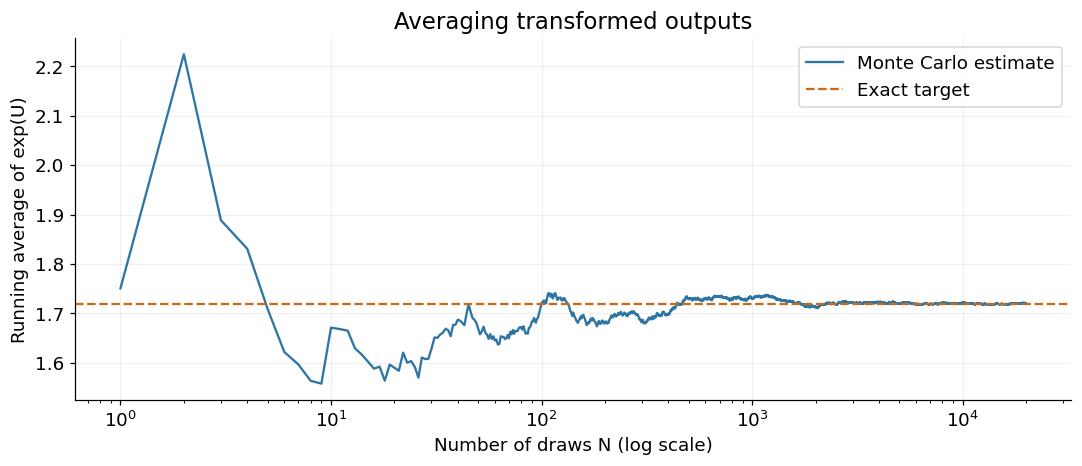

In [26]:
# PowerPoint: Slide 34 (cell 1/2) — Estimating the expectation of exp(U)
# After this demonstration: return to Slide 35.
N_EXPECTATION = 20_000
rng_expectation = np.random.default_rng(63)
expectation_u = rng_expectation.uniform(0, 1, N_EXPECTATION)
expectation_y = np.exp(expectation_u)
expectation_estimate = expectation_y.mean()
expectation_mcse = expectation_y.std(ddof=1) / np.sqrt(N_EXPECTATION)
print(f"Average transformed draws: {expectation_estimate:.6f}")
print(f"Transform the average instead: {np.exp(expectation_u.mean()):.6f}")
print(f"Exact target e − 1: {np.e - 1:.6f}; estimated SE: {expectation_mcse:.6f}")

expectation_counts = np.arange(1, N_EXPECTATION + 1)
fig, ax = plt.subplots()
ax.plot(expectation_counts, np.cumsum(expectation_y) / expectation_counts,
        label="Monte Carlo estimate", color=BLUE)
ax.axhline(np.e - 1, color=ORANGE, linestyle="--", label="Exact target")
ax.set(xscale="log", xlabel="Number of draws N (log scale)",
       ylabel="Running average of exp(U)", title="Averaging transformed outputs")
ax.legend()
fig.tight_layout()
plt.show()

For an analytic check on precision,

$$E[Y^2]=\int_0^1e^{2u}\,du=\frac{e^2-1}{2},$$
$$\operatorname{Var}(Y)=\frac{e^2-1}{2}-(e-1)^2\approx0.24204.$$

Thus the theoretical SE is $\sqrt{0.24204/N}$. A fresh seed changes the estimate,
not this target or theoretical precision. This is also website Exercise 5.

<a id="ppt-slide-34-part-2"></a>

**PowerPoint: Slide 34 (cell 2/2).** Estimating the expectation of exp(U). Return to **Slide 35** after the demonstration. [Slide index](#powerpoint-index).


In [27]:
# PowerPoint: Slide 34 (cell 2/2) — Estimating the expectation of exp(U)
# Uses: Slide 34, cell 1 (run the earlier labelled cells first).
# After this demonstration: return to Slide 35.
expectation_variance = (np.e ** 2 - 1) / 2 - (np.e - 1) ** 2
print(f"Theoretical Monte Carlo SE: {np.sqrt(expectation_variance / N_EXPECTATION):.6f}")
print(f"Estimated Monte Carlo SE:   {expectation_mcse:.6f}")

Theoretical Monte Carlo SE: 0.003479
Estimated Monte Carlo SE:   0.003497


## Slide 35: Random points in a square and circle (Exercise 4)

Draw independent $U,V\sim\operatorname{Uniform}(-1,1)$. The joint density is constant on the square, so probability is area divided by area:
$$P(U^2+V^2\leq1)=\frac{\pi}{4}.$$


<a id="ppt-slide-35"></a>

**PowerPoint: Slide 35 · Optional.** Random points in a square and circle. This picture has its own seed and 2,000 points. It illustrates the same model as the slide, but is a different simulated run. Return to **Slide 36** after the demonstration. [Slide index](#powerpoint-index).


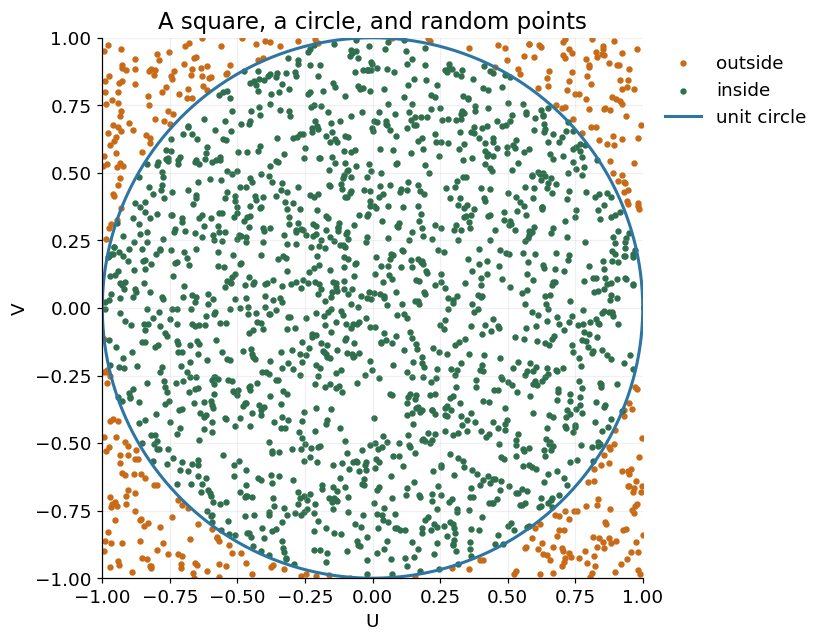

In [28]:
# PowerPoint: Slide 35 — Random points in a square and circle
# After this demonstration: return to Slide 36.
# One separate run for the picture
pi_plot_rng = np.random.default_rng(2027)
pi_xy = pi_plot_rng.uniform(-1, 1, size=(2_000, 2))
pi_inside = (pi_xy[:, 0]**2 + pi_xy[:, 1]**2 <= 1)
pi_angle = np.linspace(0, 2*np.pi, 400)
fig, ax = plt.subplots(figsize=(7.8, 6))
ax.scatter(pi_xy[~pi_inside,0], pi_xy[~pi_inside,1], s=10, color=ORANGE, label="outside")
ax.scatter(pi_xy[pi_inside,0], pi_xy[pi_inside,1], s=10, color=GREEN, label="inside")
ax.plot(np.cos(pi_angle), np.sin(pi_angle), color=BLUE, lw=2, label="unit circle")
ax.set(xlim=(-1,1), ylim=(-1,1), aspect="equal", xlabel="U", ylabel="V", title="A square, a circle, and random points")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
fig.tight_layout(); plt.show()

## Slide 36: The pi estimator and its standard error

Let $K$ be the number of the $N$ points that fall inside the circle. Then $\widehat p=K/N$, so
$$\widehat{\pi}=4\widehat p=4K/N,
\qquad \widehat{\operatorname{SE}}(\widehat\pi)=4\sqrt{\frac{\widehat p(1-\widehat p)}{N}}.$$
The factor 4 rescales both the estimate and its standard error.

**Predict.** If $N$ is multiplied by 100, what should happen to the typical Monte Carlo standard error? Change the seed or trial counts after predicting.

<a id="ppt-slide-36"></a>

**PowerPoint: Slide 36 · Optional.** Estimating pi and its Monte Carlo SE. This table uses different seeds and trial counts from the fixed slide example. Expect different estimates, with the same target pi. Return to **Slide 37** after the demonstration. [Slide index](#powerpoint-index).


In [29]:
# PowerPoint: Slide 36 — Estimating pi and its Monte Carlo SE
# After this demonstration: return to Slide 37.
# Editable parameters
pi_seed = 2026
pi_trial_counts = [100, 1_000, 10_000, 100_000]
pi_rng = np.random.default_rng(pi_seed)
pi_rows = []
for pi_N in pi_trial_counts:
    pi_xy = pi_rng.uniform(-1, 1, size=(pi_N, 2))
    pi_inside = (pi_xy[:, 0]**2 + pi_xy[:, 1]**2 <= 1)
    pi_p_hat = pi_inside.mean()
    pi_rows.append((pi_N, pi_inside.sum(), 4*pi_p_hat,
                    4*np.sqrt(pi_p_hat*(1-pi_p_hat)/pi_N)))
pi_table = pd.DataFrame(pi_rows, columns=["N", "points inside", "pi estimate", "estimated SE"])
display(pi_table.style.format({"pi estimate": "{:.5f}", "estimated SE": "{:.5f}"}))

,N,points inside,pi estimate,estimated SE
0,100,83,3.32000,0.15025
1,1000,794,3.17600,0.05116
2,10000,7889,3.15560,0.01632
3,100000,78699,3.14796,0.00518


**Interpretation.** The area ratio gives the target, while the indicator average gives a random estimate. Four times as many points should roughly halve the standard error, not quarter it.

## Slide 37: Monte Carlo integration

Let $U\sim\operatorname{Uniform}(a,b)$. Its density is $1/(b-a)$, so

$$E[f(U)]=\frac1{b-a}\int_a^b f(u)\,du.$$

Rearrange and estimate the expectation by an average:

$$\boxed{\int_a^b f(u)\,du
\approx (b-a)\frac1N\sum_{i=1}^N f(U_i).}$$

For $f(u)=u^2$ on $[0,2]$, the integral is $8/3$. We use this easy integral so we
can check the method. In harder models, an exact answer may be unavailable.

**Predict:** why is `mean(U**2)` alone too small? What does it estimate?

<a id="ppt-slide-37"></a>

**PowerPoint: Slide 37.** Monte Carlo integration. Return to **Slide 38** after the demonstration. [Slide index](#powerpoint-index).


Average height: 1.32577 (target 4/3)
Width × average height: 2.65154 (target 8/3)
Estimated Monte Carlo SE for the integral: 0.01680


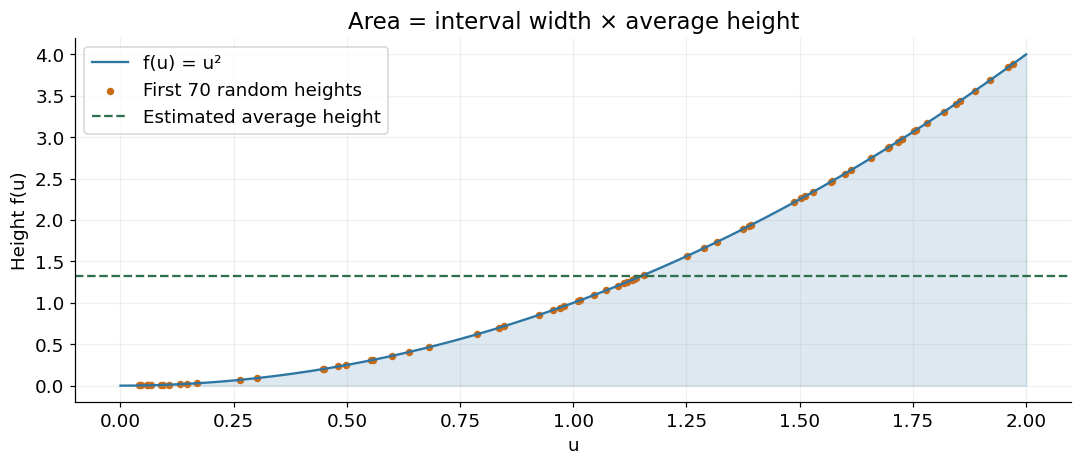

In [30]:
# PowerPoint: Slide 37 — Monte Carlo integration
# After this demonstration: return to Slide 38.
N_INTEGRAL = 20_000
a_integral, b_integral = 0.0, 2.0
rng_integral = np.random.default_rng(64)
integral_u = rng_integral.uniform(a_integral, b_integral, N_INTEGRAL)
integral_heights = integral_u ** 2
integral_outputs = (b_integral - a_integral) * integral_heights
integral_estimate = integral_outputs.mean()
integral_mcse = integral_outputs.std(ddof=1) / np.sqrt(N_INTEGRAL)
print(f"Average height: {integral_heights.mean():.5f} (target 4/3)")
print(f"Width × average height: {integral_estimate:.5f} (target 8/3)")
print(f"Estimated Monte Carlo SE for the integral: {integral_mcse:.5f}")

curve_x = np.linspace(a_integral, b_integral, 300)
fig, ax = plt.subplots()
ax.fill_between(curve_x, curve_x ** 2, alpha=0.16, color=BLUE)
ax.plot(curve_x, curve_x ** 2, label="f(u) = u²", color=BLUE)
ax.scatter(integral_u[:70], integral_heights[:70], s=15, color=ORANGE,
           label="First 70 random heights")
ax.axhline(integral_heights.mean(), linestyle="--", color=GREEN,
           label="Estimated average height")
ax.set(xlabel="u", ylabel="Height f(u)", title="Area = interval width × average height")
ax.legend()
fig.tight_layout()
plt.show()

## Slide 38: Optional rare-event demonstration (Exercise 8)

For event probability $p=0.001$, the estimate is the mean of independent 0/1 indicators, with theoretical standard error $\sqrt{p(1-p)/N}$. A binomial count is allowed here because it is the sum of familiar independent Bernoulli indicators.

**Predict.** With $N=1{,}000$, how often should a complete run have zero hits? Does zero hits mean the event probability is zero?

<a id="ppt-slide-38"></a>

**PowerPoint: Slide 38 (cell 1/3) · Optional.** Rare events and zero-hit runs. Run the three labelled cells in order. Zero observed hits do not establish zero probability or zero uncertainty. [Next cell for this slide](#ppt-slide-38-part-2). Return to **Slide 39** after the demonstration. [Slide index](#powerpoint-index).


In [31]:
# PowerPoint: Slide 38 (cell 1/3) — Rare events and zero-hit runs
# After this demonstration: return to Slide 39.
rare_p = 0.001
rare_trial_counts = [1_000, 10_000, 100_000, 1_000_000]
rare_rows = [(rare_N, rare_N*rare_p, np.sqrt(rare_p*(1-rare_p)/rare_N))
             for rare_N in rare_trial_counts]
rare_table = pd.DataFrame(rare_rows, columns=["N", "expected hits Np", "theoretical SE of p-hat"])
display(rare_table.style.format({"expected hits Np": "{:.1f}", "theoretical SE of p-hat": "{:.6f}"}))
print("N for theoretical SE <= 0.0001:", int(np.ceil(rare_p*(1-rare_p)/0.0001**2)))

,N,expected hits Np,theoretical SE of p-hat
0,1000,1.0,0.000999
1,10000,10.0,0.000316
2,100000,100.0,0.000100
3,1000000,1000.0,0.000032


N for theoretical SE <= 0.0001: 99901


<a id="ppt-slide-38-part-2"></a>

**PowerPoint: Slide 38 (cell 2/3) · Optional.** Rare events and zero-hit runs. [Next cell for this slide](#ppt-slide-38-part-3). Return to **Slide 39** after the demonstration. [Slide index](#powerpoint-index).


In [32]:
# PowerPoint: Slide 38 (cell 2/3) — Rare events and zero-hit runs
# Uses: Slide 38, cell 1 (run the earlier labelled cells first).
# After this demonstration: return to Slide 39.
# Binomial(n,p) is the count of n independent Bernoulli(p) indicators.
rare_rng = np.random.default_rng(2506)
rare_small_N, rare_runs = 1_000, 20_000
rare_small_counts = rare_rng.binomial(rare_small_N, rare_p, size=rare_runs)
print(f"Simulated fraction of zero-hit runs: {(rare_small_counts==0).mean():.3f}")
print(f"Theoretical P(zero hits):           {(1-rare_p)**rare_small_N:.3f}")

Simulated fraction of zero-hit runs: 0.371
Theoretical P(zero hits):           0.368


<a id="ppt-slide-38-part-3"></a>

**PowerPoint: Slide 38 (cell 3/3) · Optional.** Rare events and zero-hit runs. Return to **Slide 39** after the demonstration. [Slide index](#powerpoint-index).


In [33]:
# PowerPoint: Slide 38 (cell 3/3) — Rare events and zero-hit runs
# Uses: Slide 38, cell 1 (run the earlier labelled cells first).
# After this demonstration: return to Slide 39.
# One run at each larger N. A zero plug-in SE is not genuine zero uncertainty.
rare_one_rng = np.random.default_rng(2507)
rare_one_rows = []
for rare_N in rare_trial_counts:
    rare_hits = rare_one_rng.binomial(rare_N, rare_p)
    rare_p_hat = rare_hits/rare_N
    rare_one_rows.append((rare_N, rare_hits, rare_p_hat,
                          np.sqrt(rare_p_hat*(1-rare_p_hat)/rare_N)))
rare_one_table = pd.DataFrame(rare_one_rows, columns=["N", "hits", "p-hat", "plug-in SE"])
display(rare_one_table.style.format({"p-hat": "{:.6f}", "plug-in SE": "{:.6f}"}))
print("Caution: with zero or very few hits, plug-in SEs and normal intervals are unreliable.")

,N,hits,p-hat,plug-in SE
0,1000,0,0.000000,0.000000
1,10000,8,0.000800,0.000283
2,100000,99,0.000990,0.000099
3,1000000,937,0.000937,0.000031


Caution: with zero or very few hits, plug-in SEs and normal intervals are unreliable.


## Slide 39: What if capacity falls to 105?

**Predict:** suppose capacity falls from 110 to 105. Which target changes: the
expected workload, the probability of fitting, or both?

<a id="ppt-slide-39"></a>

**PowerPoint: Slide 39.** What if capacity falls to 105? Ask for a prediction first. Read the row for capacity 105. The histogram still marks the original capacity of 110 for comparison. Return to **Slide 40** after the demonstration. [Slide index](#powerpoint-index).


,Capacity,Estimated probability of fitting
0,100,0.84377
1,105,0.92541
2,110,0.96818
3,115,0.98787
4,120,0.99596


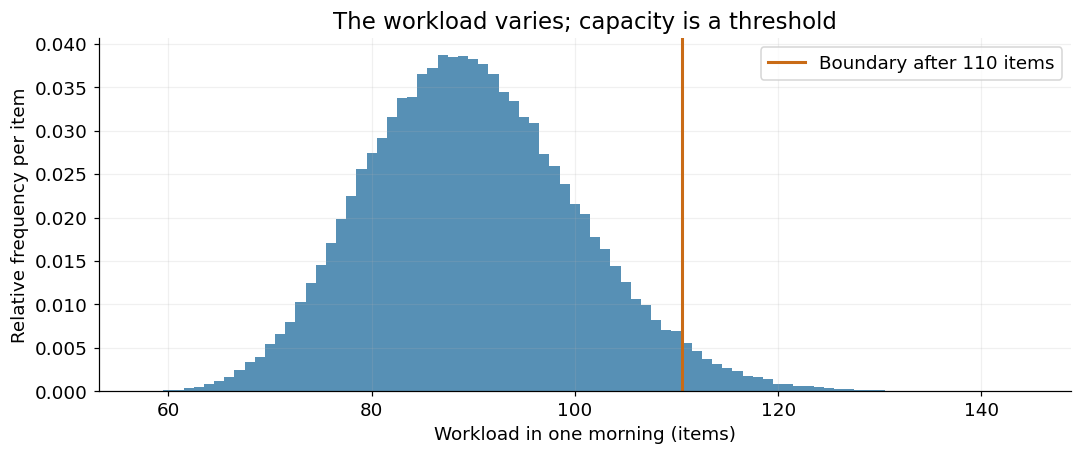

In [34]:
# PowerPoint: Slide 39 — What if capacity falls to 105?
# Uses: Slide 14 (run the earlier labelled cells first).
# After this demonstration: return to Slide 40.
# A live what-if experiment: change the capacity, keeping the same workloads.
demo_capacities = np.array([100, 105, 110, 115, 120])
capacity_probabilities = np.array([(workloads <= c).mean() for c in demo_capacities])
display(pd.DataFrame({"Capacity": demo_capacities,
                      "Estimated probability of fitting": capacity_probabilities}))

fig, ax = plt.subplots(figsize=(10, 4.3))
bins = np.arange(workloads.min() - 0.5, workloads.max() + 1.5)
ax.hist(workloads, bins=bins, density=True, color=BLUE, alpha=0.8)
ax.axvline(CAPACITY + 0.5, color=ORANGE, linewidth=2,
           label=f"Boundary after {CAPACITY} items")
ax.set(xlabel="Workload in one morning (items)", ylabel="Relative frequency per item",
       title="The workload varies; capacity is a threshold")
ax.legend()
fig.tight_layout()
plt.show()

The workload distribution and its mean have not changed. Only the event used to
classify a morning has changed. Using the same simulated mornings makes this
comparison easy to see; the estimates in the table are therefore related, not
independent experiments.

The histogram uses bins one item wide. A bin centred at 110 extends to 110.5,
which is why the plotted boundary comes just after 110. These are the same
half-item boundaries discussed with the normal approximation on Slide 24.

## Slide 39B: Optional model-change experiment

A precise answer to the wrong model can still be wrong for the real warehouse.
Changing the frequency of large orders changes the target itself. Increasing $N$
only improves our numerical answer for whichever model we choose.

**Predict:** what happens if six-item orders occur with probability 0.15 instead
of 0.10, taking the extra 0.05 from one-item orders?

<a id="ppt-slide-39b"></a>

**PowerPoint: Slide 39B · Optional.** Optional extension: changing the warehouse model. This changes the order probabilities, whereas Slide 39 changes capacity only. It is a separate what-if question, not the answer to the capacity question. Return to **Slide 40** after the demonstration. [Slide index](#powerpoint-index).


In [35]:
# PowerPoint: Slide 39B — Optional extension: changing the warehouse model
# Uses: Slide 4 model setup (run the earlier labelled cells first).
# After this demonstration: return to Slide 40.
N_MODEL_COMPARISON = 20_000
comparison_rows = []
for label, probabilities in [("Baseline", [0.60, 0.30, 0.10]),
                             ("More large orders", [0.55, 0.30, 0.15])]:
    # Deliberately reuse the seed for a reproducible comparison between models.
    rng_model = np.random.default_rng(62)
    model_totals = rng_model.choice(ORDER_VALUES,
                    size=(N_MODEL_COMPARISON, ORDERS_PER_MORNING),
                    p=probabilities).sum(axis=1)
    comparison_rows.append({"Model": label,
        "Exact expected workload": ORDERS_PER_MORNING * np.dot(ORDER_VALUES, probabilities),
        "Estimated probability within capacity": (model_totals <= CAPACITY).mean()})
display(pd.DataFrame(comparison_rows).set_index("Model"))

,Exact expected workload,Estimated probability within capacity
Model,,
Baseline,90.0,0.97045
More large orders,102.5,0.74705


<a id="summary"></a>
## Slide 40: Closing summary

**Before writing code, say what one complete trial produces.** Then ask what the
average of that output estimates.

| Output from one trial | Average estimates |
|:--|:--|
| One morning's workload | Expected workload |
| 1 if the morning fits, 0 otherwise | Probability of fitting |
| $e^U$ | $E[e^U]$ |
| $(b-a)f(U)$, with uniform $U$ on $[a,b]$ | $\int_a^b f(u)\,du$ |

The LLN explains concentration near the target. The CLT explains approximate
normality of a standardised average and supports uncertainty calculations when
its approximation is adequate. More simulations improve numerical precision
within the model; they do not establish that the model is realistic.

**Exit questions**

1. Why does the warehouse probability not converge to 90?
2. What is the difference between increasing $n$ and increasing $N$?
3. What is the difference between output SD and Monte Carlo SE?
4. Why does halving the SE take about four times as many trials?
5. Which assumption justifies adding variances in the sample-mean derivation?

<details><summary>Discussion guide — open after students answer</summary>
<p>1. 90 is expected items; the capacity estimate averages event indicators.
2. n changes the trial itself; N changes the number of repeated trials.
3. Output SD describes individual outcomes; SE describes repeated estimates.
4. SE is inversely proportional to the square root of N.
5. Independence makes the cross-covariances zero.</p>
</details>

### Formula reference

For i.i.d. observations with mean $\mu$ and finite variance $\sigma^2$:

$$E[\bar X_n]=\mu,\qquad \operatorname{Var}(\bar X_n)=\frac{\sigma^2}{n},
\qquad E[S_n]=n\mu,\qquad \operatorname{Var}(S_n)=n\sigma^2.$$

For i.i.d. simulated outputs with a finite mean and positive finite variance:

$$\widehat\theta_N=\frac1N\sum_iY_i,\quad
\widehat{\operatorname{SE}}(\widehat\theta_N)=\frac{s_Y}{\sqrt N},\quad
s_Y^2=\frac1{N-1}\sum_i(Y_i-\widehat\theta_N)^2.$$

For a probability:

$$\widehat p_N=\frac{\text{hits}}N,\qquad
\widehat{\operatorname{SE}}(\widehat p_N)
=\sqrt{\frac{\widehat p_N(1-\widehat p_N)}N}.$$

Approximate 95% interval: estimate $\pm1.96\times$ estimated SE, when the normal
approximation is appropriate. For rare event indicators, check that there are
enough hits and non-hits. LLN needs finite expected absolute output; the ordinary
CLT used here additionally needs finite positive variance.

<a id="optional-labs"></a>
## Slide 41: Exercise demonstrations

The optional examples now sit alongside their matching slides. Their content is unchanged.

| Exercise | Notebook location |
|---|---|
| 1: Normal water samples | Slide 41A below |
| 2: Skewed tree counts | [Slide 21](#ppt-slide-21) |
| 3: Annual accident totals | [Slide 24](#ppt-slide-24) and Slide 41B below |
| 4: Estimating pi | [Slides 35](#ppt-slide-35) and [36](#ppt-slide-36) |
| 5: Expectation of exp(U) | [Slide 34](#ppt-slide-34) |
| 6: Bernoulli LLN paths | [Slide 18B](#ppt-slide-18b) |
| 7: Uniform sample means | [Slides 11](#ppt-slide-11) and [20](#ppt-slide-20) |
| 8: Rare-event precision | [Slide 38](#ppt-slide-38) |

The optional instructor benchmark remains at [Slide 23B](#ppt-slide-23b).


## Slide 41A: Optional exact normal sampling example (Exercise 1)

Assume the water measurements are normally distributed, with mean $\mu=7.48$ mg/L and standard deviation $\sigma=1.60$ mg/L. Thus
$$X\sim\operatorname{Normal}(7.48,1.60^2).$$
For $n=10$ independent measurements,
$$\bar X\sim\operatorname{Normal}(7.48,1.60^2/10)$$
exactly — no CLT approximation is needed because the original observations are normal. Thus
$$P(6.49<\bar X<8.47)=
\Phi\!\left(\frac{8.47-7.48}{1.60/\sqrt{10}}\right)-
\Phi\!\left(\frac{6.49-7.48}{1.60/\sqrt{10}}\right)
\approx0.9496.$$
Normality is an assumption here; a mean and standard deviation alone do not imply it.

**Predict.** Is $P(6.49<\bar X<8.47)$ close to 0.50, 0.95, or 1? Why is the distribution of $\bar X$ narrower than the distribution of one measurement $X$?

<a id="ppt-slide-41a"></a>

**PowerPoint: Slide 41A (cell 1/2) · Optional.** Exercise extension: exact normal sampling. Related to Slide 21. Do this here, after the introduction of Monte Carlo SE on Slide 28. Run both labelled cells. [Next cell for this slide](#ppt-slide-41a-part-2). Return to **Slide 41** after the demonstration. [Slide index](#powerpoint-index).


In [36]:
# PowerPoint: Slide 41A (cell 1/2) — Exercise extension: exact normal sampling
# After this demonstration: return to Slide 41.
# Editable parameters
water_mu, water_sd, water_n, water_repetitions = 7.48, 1.60, 10, 20_000
water_rng = np.random.default_rng(2206)
water_se_exact = water_sd/np.sqrt(water_n)
water_lower, water_upper = 6.49, 8.47
water_exact = (stats.norm.cdf(water_upper, loc=water_mu, scale=water_se_exact)
               - stats.norm.cdf(water_lower, loc=water_mu, scale=water_se_exact))
water_means = water_rng.normal(water_mu, water_sd,
                               size=(water_repetitions, water_n)).mean(axis=1)
water_mc = ((water_means > water_lower) & (water_means < water_upper)).mean()
water_mcse = np.sqrt(water_mc*(1-water_mc)/water_repetitions)
print(f"Exact probability = {water_exact:.5f}")
print(f"Simulation        = {water_mc:.5f} ± {water_mcse:.5f} (MC SE)")

Exact probability = 0.94961
Simulation        = 0.95110 ± 0.00152 (MC SE)


<a id="ppt-slide-41a-part-2"></a>

**PowerPoint: Slide 41A (cell 2/2) · Optional.** Exercise extension: exact normal sampling. Return to **Slide 41** after the demonstration. [Slide index](#powerpoint-index).


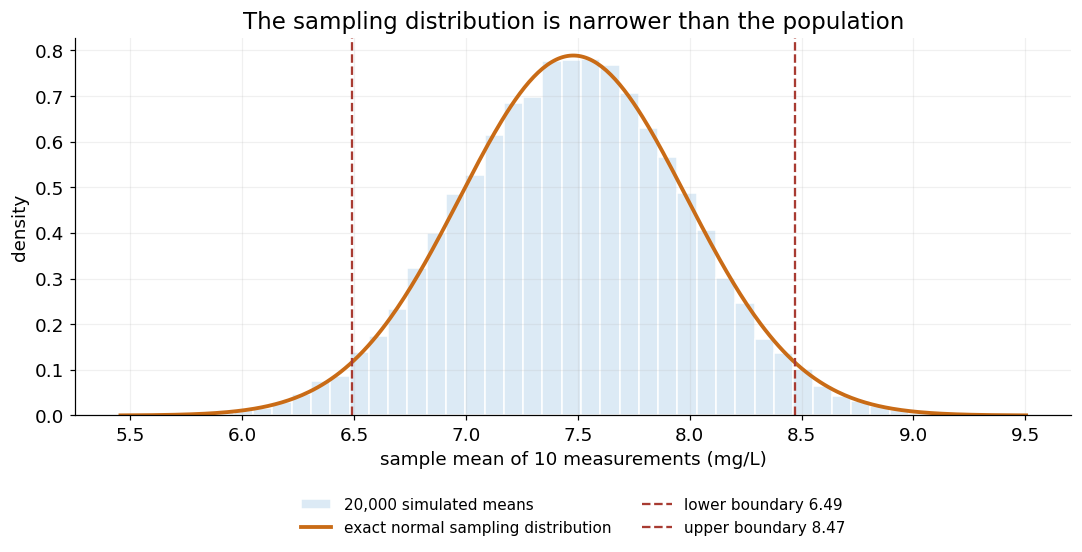

In [37]:
# PowerPoint: Slide 41A (cell 2/2) — Exercise extension: exact normal sampling
# Uses: Slide 41A, cell 1 (run the earlier labelled cells first).
# After this demonstration: return to Slide 41.
fig, ax = plt.subplots(figsize=(10, 5.3))
ax.hist(water_means, bins=45, density=True, color="#DCEAF5", edgecolor="white", label=f"{water_repetitions:,} simulated means")
water_grid = np.linspace(water_mu-4*water_se_exact, water_mu+4*water_se_exact, 400)
ax.plot(water_grid, stats.norm.pdf(water_grid, water_mu, water_se_exact), color=ORANGE, lw=2.5, label="exact normal sampling distribution")
ax.axvline(water_lower, color=RED, ls="--", label=f"lower boundary {water_lower}")
ax.axvline(water_upper, color=RED, ls="--", label=f"upper boundary {water_upper}")
ax.set(xlabel=f"sample mean of {water_n} measurements (mg/L)", ylabel="density",
       title="The sampling distribution is narrower than the population")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2,
          fontsize=10, frameon=False)
fig.tight_layout(); plt.show()

## Slide 41B: Optional daily-by-daily accident simulation (Exercise 3)

This revisits the independent Poisson(10) daily counts from Slide 24. Run its approximation cell first if you skipped it, then simulate whole years and compare the resulting probability.

<a id="ppt-slide-41b"></a>

**PowerPoint: Slide 41B (cell 1/2) · Optional.** Exercise extension: daily-by-daily accident simulation. Run the Slide 24 approximation cell first if it has not already run, then these two cells. This extends the approximation with simulation and MCSE. [Next cell for this slide](#ppt-slide-41b-part-2). Return to **Slide 41** after the demonstration. [Slide index](#powerpoint-index).


In [38]:
# PowerPoint: Slide 41B (cell 1/2) — Exercise extension: daily-by-daily accident simulation
# Uses: Slide 24 (run the earlier labelled cells first).
# After this demonstration: return to Slide 41.
# Simulate DAILY counts directly in batches: no annual-distribution shortcut.
acc_rng = np.random.default_rng(2306)
acc_years, acc_batch_size, acc_hits, acc_done, acc_examples = 50_000, 2_000, 0, 0, []
while acc_done < acc_years:
    acc_current = min(acc_batch_size, acc_years-acc_done)
    acc_daily = acc_rng.poisson(acc_daily_mean, size=(acc_current, acc_days))
    acc_totals = acc_daily.sum(axis=1)
    acc_hits += (acc_totals > acc_cutoff).sum()
    acc_examples.extend(acc_totals[:max(0, 2_000-len(acc_examples))])
    acc_done += acc_current
acc_p_hat = acc_hits/acc_years
acc_mcse = np.sqrt(acc_p_hat*(1-acc_p_hat)/acc_years)
print(f"Daily-by-daily simulation: {acc_p_hat:.6f} ± {acc_mcse:.6f} (MC SE)")

Daily-by-daily simulation: 0.006740 ± 0.000366 (MC SE)


<a id="ppt-slide-41b-part-2"></a>

**PowerPoint: Slide 41B (cell 2/2) · Optional.** Exercise extension: daily-by-daily accident simulation. Return to **Slide 41** after the demonstration. [Slide index](#powerpoint-index).


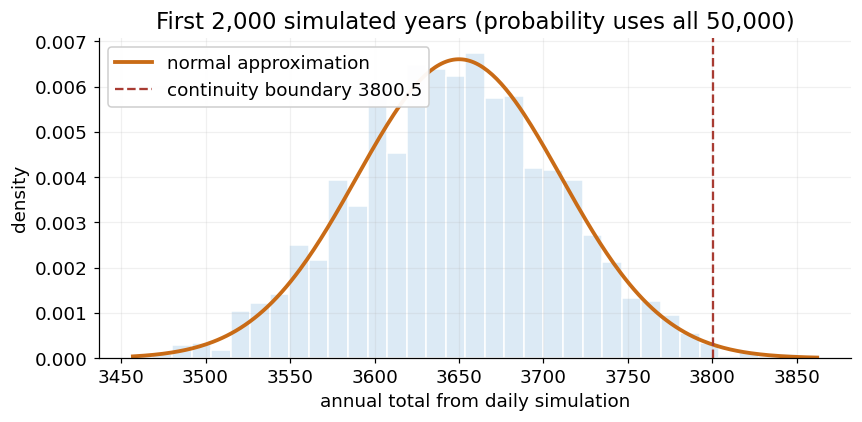

In [39]:
# PowerPoint: Slide 41B (cell 2/2) — Exercise extension: daily-by-daily accident simulation
# Uses: Slide 24 and Slide 41B, cell 1 (run the earlier labelled cells first).
# After this demonstration: return to Slide 41.
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(acc_examples, bins=35, density=True, color="#DCEAF5", edgecolor="white")
acc_grid = np.linspace(min(acc_examples), max(acc_examples), 300)
ax.plot(acc_grid, stats.norm.pdf(acc_grid, acc_mean, acc_sd), color=ORANGE, lw=2.5, label="normal approximation")
ax.axvline(acc_cutoff+0.5, color=RED, ls="--", label=f"continuity boundary {acc_cutoff+0.5}")
ax.set(xlabel="annual total from daily simulation", ylabel="density",
       title=f"First {len(acc_examples):,} simulated years (probability uses all {acc_years:,})")
ax.legend(loc="upper left", frameon=True, facecolor="white", framealpha=.95)
fig.tight_layout(); plt.show()

<a id="powerpoint-index"></a>

## PowerPoint: slide-to-code index

The notebook is physically arranged in this slide order. Run setup, then work down the cells and return to PowerPoint at each cue. All code cells also carry their slide label as a comment.

| Slide | Notebook demonstration | Return to |
|---|---|---|
| Setup | [Before the presentation](#ppt-setup) | Slide 1 |
| Slide 4 | [One simulated morning](#ppt-slide-4) | Slide 5 |
| Slide 5 (optional) | [Where the randomness comes from](#ppt-slide-5) | Slide 6 |
| Slide 11 (cell 1 prepares Slide 20) | [Sampling distributions and their spread](#ppt-slide-11) | Slide 12 |
| Slide 14 | [Simulating many mornings](#ppt-slide-14) | Slide 15 |
| Slide 15 | [Reading the simulation results](#ppt-slide-15) | Slide 16 |
| Slide 16 (optional) | [Revisit the Slide 14 cell: change the seed, then restore 6](#ppt-slide-14) | Slide 17 |
| Slide 18 | [LLN: two running averages](#ppt-slide-18) | Slide 19 |
| Slide 18B (optional) | [Optional LLN extension: several Bernoulli paths](#ppt-slide-18b) | Slide 19 |
| Slide 20 | [CLT: standardised means](#ppt-slide-20) | Slide 21 |
| Slide 21 (optional) | [Optional CLT extension: a skewed population](#ppt-slide-21) | Slide 22 |
| Slide 23 (optional) | [Warehouse probability: normal approximation and simulation](#ppt-slide-23) | Slide 24 |
| Slide 23B (optional) | [Instructor extension: a direct warehouse benchmark](#ppt-slide-23b) | Slide 24 |
| Slide 24 (optional) | [Normal approximation to an annual count](#ppt-slide-24) | Slide 25 |
| Slide 28 | [Monte Carlo standard errors](#ppt-slide-28) | Slide 29 |
| Slide 30 (optional) | [What 95% coverage means](#ppt-slide-30) | Slide 31 |
| Slide 31 (optional) | [Reporting the warehouse probability and interval](#ppt-slide-31) | Slide 32 |
| Slide 32 (optional) | [Planning the number of trials](#ppt-slide-32) | Slide 33 |
| Slide 34 | [Estimating the expectation of exp(U)](#ppt-slide-34) | Slide 35 |
| Slide 35 (optional) | [Random points in a square and circle](#ppt-slide-35) | Slide 36 |
| Slide 36 (optional) | [Estimating pi and its Monte Carlo SE](#ppt-slide-36) | Slide 37 |
| Slide 37 | [Monte Carlo integration](#ppt-slide-37) | Slide 38 |
| Slide 38 (optional) | [Rare events and zero-hit runs](#ppt-slide-38) | Slide 39 |
| Slide 39 | [What if capacity falls to 105?](#ppt-slide-39) | Slide 40 |
| Slide 39B (optional) | [Optional extension: changing the warehouse model](#ppt-slide-39b) | Slide 40 |
| Slide 41A (optional) | [Exercise extension: exact normal sampling](#ppt-slide-41a) | Slide 41 |
| Slide 41B (optional) | [Exercise extension: daily-by-daily accident simulation](#ppt-slide-41b) | Slide 41 |

**Slide 33:** the trial-count scaling table is in the [Slide 32 cell](#ppt-slide-32). It uses warehouse indicators rather than exp(U).

**Slide 41:** the exercise extensions above include exact normal sampling (41A) and annual accidents (41B). The [Bernoulli LLN](#ppt-slide-18b), [rare-event](#ppt-slide-38) and [skewed-population](#ppt-slide-21) examples are also available.
